# 04. Model Training - atual (n=40)

In [5]:
# Aprendizado de Máquina | SVM LINEAR (5-FOLD CV | N = 40 PARTICIPANTES PAREADOS)

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

warnings.filterwarnings('ignore')

# 1. Carregamento e Preparação da Amostra
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

# Filtragem pela condição de interesse e consolidação por participante
df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Remoção dos IDs despareados/com artefato (13, 34 e 42)
ids_remover = [13, 34, 42]
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num']).reset_index(drop=True)

# Definição dos vetores de treino (X) e alvos (y: 1 = TEA, 0 = Controle)
y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

features_ouro = [
    'AlphaRel_P3',
    'AlphaRel_Fp2',
    'BetaRel_F7',
    'AlphaRel_F8',
    'GammaRel_F7'
]
X = df_f[features_ouro].values

# 2. Pipeline do Modelo Vencedor (StandardScaler + SVM Linear Balanced)
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='linear', class_weight='balanced', random_state=42))
])

# Validação Cruzada 5-Fold Estratificada
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

# 3. Predição Cega Fora da Amostra (Out-of-Fold)
y_pred = cross_val_predict(pipeline_svm, X, y, cv=cv_strategy)

# 4. Extração e Cálculo das Métricas Quantitativas
tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()

total_amostra = len(df_f)
total_controle = tn + fp
total_tea = tp + fn

acuracia = (tp + tn) / total_amostra
sensibilidade = tp / (tp + fn)     # Recall / TPR (Sensibilidade para classe TEA)
especificidade = tn / (tn + fp)     # TNR (Sensibilidade para classe Controle)
precisao = tp / (tp + fp)           # Valor Preditivo Positivo
f1 = 2 * (precisao * sensibilidade) / (precisao + sensibilidade)

# 5. Exibição Estruturada dos Resultados
print("=" * 55)
print(f"      DESEMPENHO DO MODELO FINAL — SVM LINEAR")
print(f"      Amostra Pareada: N = {total_amostra} (TEA: {total_tea} | Controle: {total_controle})")
print("=" * 55)
print(f"Acurácia Global:   {acuracia:.4f} ({acuracia * 100:.2f}%)")
print(f"Sensibilidade:     {sensibilidade:.4f} ({sensibilidade * 100:.2f}%)")
print(f"Especificidade:    {especificidade:.4f} ({especificidade * 100:.2f}%)")
print(f"Precisão:          {precisao:.4f} ({precisao * 100:.2f}%)")
print(f"F1-Score:          {f1:.4f}")
print("-" * 55)
print("Detalhamento de Acertos por Classe:")
print(f"  • Grupo TEA (1):      {tp} acertos de {total_tea} ({tp/total_tea:.2%}) — Erros (FN): {fn}")
print(f"  • Grupo Controle (0): {tn} acertos de {total_controle} ({tn/total_controle:.2%}) — Erros (FP): {fp}")
print("=" * 55)

print("\nRelatório de Classificação Detalhado (Scikit-Learn):")
print(classification_report(y, y_pred, target_names=['Controle (0)', 'TEA/ASD (1)'], digits=4))

      DESEMPENHO DO MODELO FINAL — SVM LINEAR
      Amostra Pareada: N = 40 (TEA: 18 | Controle: 22)
Acurácia Global:   0.8250 (82.50%)
Sensibilidade:     0.8333 (83.33%)
Especificidade:    0.8182 (81.82%)
Precisão:          0.7895 (78.95%)
F1-Score:          0.8108
-------------------------------------------------------
Detalhamento de Acertos por Classe:
  • Grupo TEA (1):      15 acertos de 18 (83.33%) — Erros (FN): 3
  • Grupo Controle (0): 18 acertos de 22 (81.82%) — Erros (FP): 4

Relatório de Classificação Detalhado (Scikit-Learn):
              precision    recall  f1-score   support

Controle (0)     0.8571    0.8182    0.8372        22
 TEA/ASD (1)     0.7895    0.8333    0.8108        18

    accuracy                         0.8250        40
   macro avg     0.8233    0.8258    0.8240        40
weighted avg     0.8267    0.8250    0.8253        40



# Plots

In [ ]:
# VISUALIZAÇÃO: CLASSIFICATION EVALUATION (CM + MEAN ROC CURVE - SVM LINEAR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz | N = 40 Pareados)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Remoção dos Participantes Despareados/Artefato (13, 34 e 42)
ids_remover = [13, 34, 42]
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num']).reset_index(drop=True)

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis de Ouro
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Treinamento Rigoroso e Extração para ROC/CM (SVM Linear Balanced)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
svm_modelo = SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42)
scaler = StandardScaler()

tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)
y_pred_all = []
y_true_all = []

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Transformação estrita no fold (Leakage-free)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    svm_modelo.fit(X_train_scaled, y_train)
    y_proba = svm_modelo.predict_proba(X_test_scaled)[:, 1]
    y_pred = svm_modelo.predict(X_test_scaled)
    
    # Armazenamento para a Matriz de Confusão Agregada
    y_true_all.extend(y_test)
    y_pred_all.extend(y_pred)
    
    # Cálculos para a Curva ROC do fold atual
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    
    # Interpolação para padronizar o eixo X (FPR) e poder calcular a média da curva
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

# 4. Preparação do Plot (1 linha, 2 colunas)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- PLOT 1: Matriz de Confusão Agregada ---
cm = confusion_matrix(y_true_all, y_pred_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'],
            annot_kws={"size": 28, "weight": "normal"}, 
            linewidths=2, linecolor='white')

axes[0].set_title('Aggregated Confusion Matrix\n(5 Folds - SVM Linear)', pad=20)
axes[0].set_ylabel('True Label', labelpad=10)
axes[0].set_xlabel('Predicted Label', labelpad=10)

# --- PLOT 2: Mean ROC Curve ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

# Sombreamento do Desvio Padrão
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)

axes[1].plot(mean_fpr, mean_tpr, color='#2E86C1', linewidth=3,
             label=f'Mean ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})')
axes[1].fill_between(mean_fpr, tprs_lower, tprs_upper, color='#AED6F1', alpha=0.3,
                     label=r'$\pm$ 1 Standard Deviation')

# Linha de Chance (50%)
axes[1].plot([0, 1], [0, 1], linestyle='--', lw=2, color='gray', label='Chance Level', alpha=0.8)

# Ajustes de Eixos e Títulos da Curva ROC
axes[1].set_xlim([-0.05, 1.05])
axes[1].set_ylim([-0.05, 1.05])
axes[1].set_xlabel('False Positive Rate', labelpad=10)
axes[1].set_ylabel('True Positive Rate', labelpad=10)
axes[1].set_title('Receiver Operating Characteristic\n(Happy Face Condition)', pad=20)
axes[1].legend(loc="lower right", fontsize=16, frameon=False)

axes[1].grid(axis='both', linestyle='--', alpha=0.5, color='#B0B0B0')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('#DDDDDD')
axes[1].spines['bottom'].set_color('#DDDDDD')

plt.tight_layout(w_pad=6.0)

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig02_classification_evaluation_svm.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Matriz de Confusão e Curva ROC geradas e salvas em: {caminho_imagem}")
plt.show()

✅ Matriz de Confusão e Curva ROC geradas e salvas em: ../reports/figures/fig02_classification_evaluation_svm.png


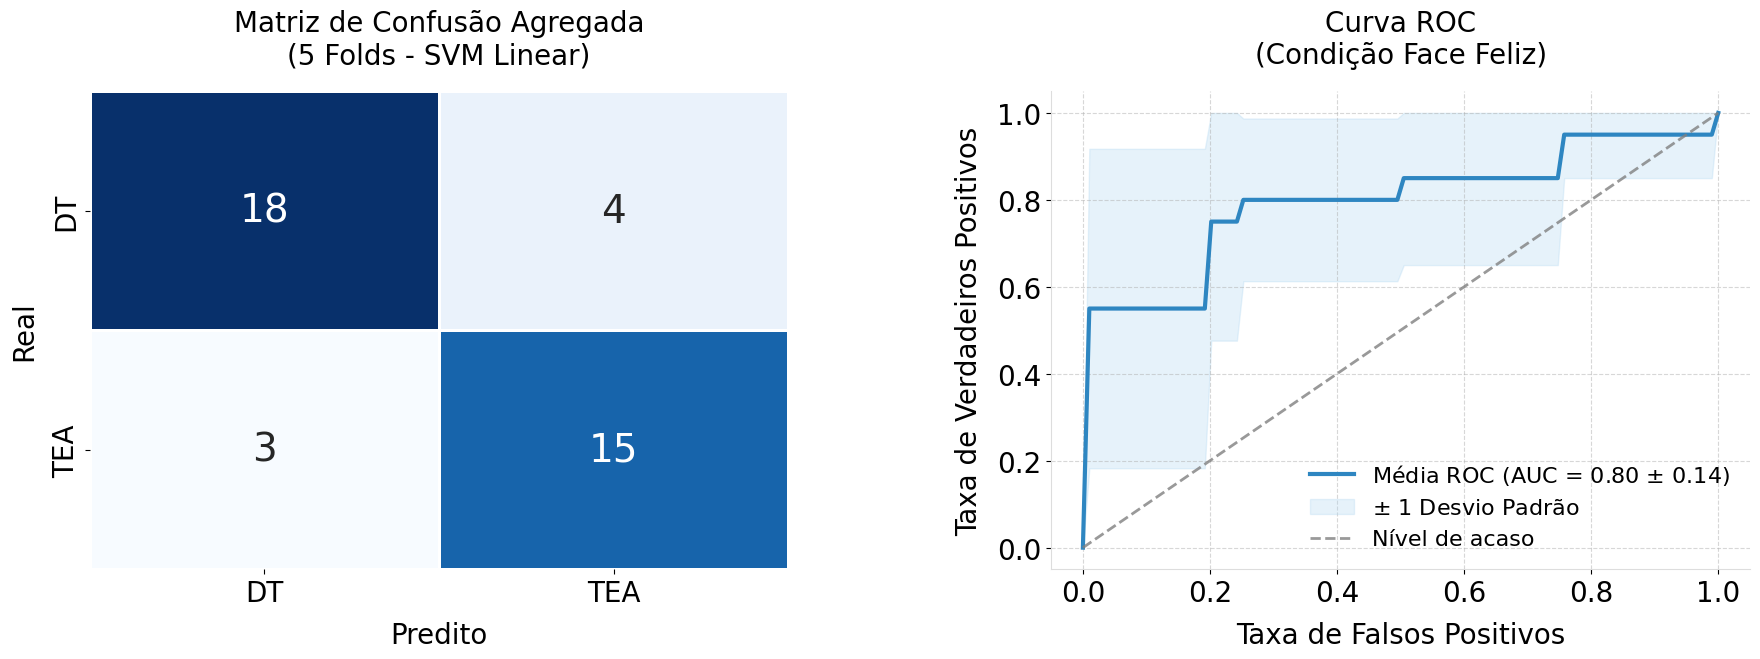

In [5]:
# VISUALIZAÇÃO: CLASSIFICATION EVALUATION (CM + MEAN ROC CURVE - SVM LINEAR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz | N = 40 Pareados)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Remoção dos Participantes Despareados/Artefato (13, 34 e 42)
ids_remover = [13, 34, 42]
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num']).reset_index(drop=True)

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis de Ouro
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Treinamento Rigoroso e Extração para ROC/CM (SVM Linear Balanced)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
svm_modelo = SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42)
scaler = StandardScaler()

tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)
y_pred_all = []
y_true_all = []

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Transformação estrita no fold (Leakage-free)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    svm_modelo.fit(X_train_scaled, y_train)
    y_proba = svm_modelo.predict_proba(X_test_scaled)[:, 1]
    y_pred = svm_modelo.predict(X_test_scaled)
    
    # Armazenamento para a Matriz de Confusão Agregada
    y_true_all.extend(y_test)
    y_pred_all.extend(y_pred)
    
    # Cálculos para a Curva ROC do fold atual
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    
    # Interpolação para padronizar o eixo X (FPR) e poder calcular a média da curva
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

# 4. Preparação do Plot (1 linha, 2 colunas)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- PLOT 1: Matriz de Confusão Agregada ---
cm = confusion_matrix(y_true_all, y_pred_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['DT', 'TEA'], yticklabels=['DT', 'TEA'],
            annot_kws={"size": 28, "weight": "normal"}, 
            linewidths=2, linecolor='white')

axes[0].set_title('Matriz de Confusão Agregada\n(5 Folds - SVM Linear)', pad=20)
axes[0].set_ylabel('Real', labelpad=10)
axes[0].set_xlabel('Predito', labelpad=10)

# --- PLOT 2: Mean ROC Curve ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

# Sombreamento do Desvio Padrão
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)

axes[1].plot(mean_fpr, mean_tpr, color='#2E86C1', linewidth=3,
             label=f'Média ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})')
axes[1].fill_between(mean_fpr, tprs_lower, tprs_upper, color='#AED6F1', alpha=0.3,
                     label=r'$\pm$ 1 Desvio Padrão')

# Linha de Chance (50%)
axes[1].plot([0, 1], [0, 1], linestyle='--', lw=2, color='gray', label='Nível de acaso', alpha=0.8)

# Ajustes de Eixos e Títulos da Curva ROC
axes[1].set_xlim([-0.05, 1.05])
axes[1].set_ylim([-0.05, 1.05])
axes[1].set_xlabel('Taxa de Falsos Positivos', labelpad=10)
axes[1].set_ylabel('Taxa de Verdadeiros Positivos', labelpad=10)
axes[1].set_title('Curva ROC\n(Condição Face Feliz)', pad=20)
axes[1].legend(loc="lower right", fontsize=16, frameon=False)

axes[1].grid(axis='both', linestyle='--', alpha=0.5, color='#B0B0B0')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('#DDDDDD')
axes[1].spines['bottom'].set_color('#DDDDDD')

plt.tight_layout(w_pad=6.0)

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig02_classification_evaluation_svm.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Matriz de Confusão e Curva ROC geradas e salvas em: {caminho_imagem}")
plt.show()

✅ Distribuição de Métricas gerada e salva em: ../reports/figures/fig01_cv_metrics_distribution_svm.png


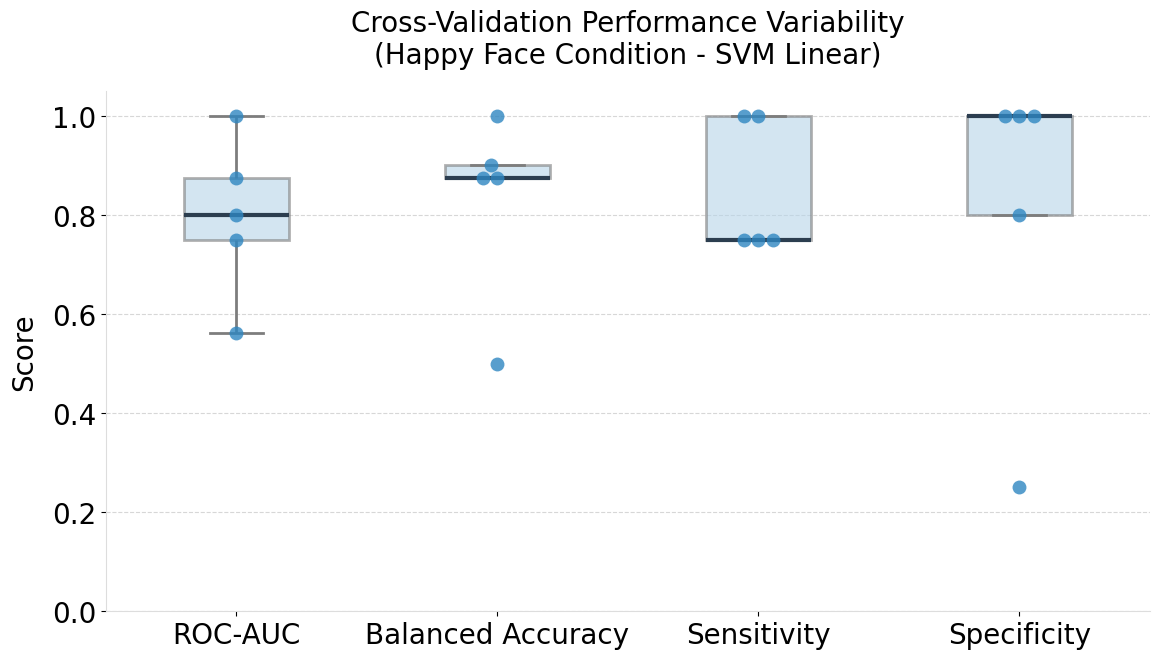


Mean Performance ± Standard Deviation:
ROC-AUC: 0.7975 ± 0.1446
Balanced Accuracy: 0.8300 ± 0.1713
Sensitivity: 0.8500 ± 0.1225
Specificity: 0.8100 ± 0.2905
ROC-AUC: 79.75% (±14.46%)
Balanced Accuracy: 83.00% (±17.13%)
Sensitivity: 85.00% (±12.25%)
Specificity: 81.00% (±29.05%)


In [2]:
# VISUALIZAÇÃO: CROSS-VALIDATION PERFORMANCE VARIABILITY (SVM LINEAR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, recall_score, confusion_matrix
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz | N = 40 Pareados)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Remoção dos Participantes Despareados/Artefato (13, 34 e 42)
ids_remover = [13, 34, 42]
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num']).reset_index(drop=True)

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis de Ouro
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Extração Rigorosa de Métricas (5-Fold CV - SVM Linear)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
svm_modelo = SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42)
scaler = StandardScaler()

# Nomenclatura com padronização correta (Title Case)
resultados = {
    'ROC-AUC': [],
    'Balanced Accuracy': [],
    'Sensitivity': [],
    'Specificity': []
}

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Transformação estrita no fold (Leakage-free)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    svm_modelo.fit(X_train_scaled, y_train)
    y_pred = svm_modelo.predict(X_test_scaled)
    y_proba = svm_modelo.predict_proba(X_test_scaled)[:, 1]
    
    # Cálculos das métricas
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    
    resultados['ROC-AUC'].append(roc_auc_score(y_test, y_proba))
    resultados['Balanced Accuracy'].append(balanced_accuracy_score(y_test, y_pred))
    resultados['Sensitivity'].append(recall_score(y_test, y_pred)) # TPR
    resultados['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else 0) # TNR

# Formatação em DataFrame para o Seaborn
df_metricas = pd.DataFrame(resultados)
df_melted = df_metricas.melt(var_name='Metric', value_name='Score')

# 4. Preparação do Plot
fig, ax = plt.subplots(figsize=(12, 7))

# Boxplot com linha da mediana destacada
sns.boxplot(data=df_melted, x='Metric', y='Score', 
            color='#AED6F1', width=0.4, linewidth=2, 
            boxprops=dict(alpha=0.6), 
            medianprops=dict(color='#2C3E50', linewidth=3), # Mediana mais escura e grossa
            showfliers=False, ax=ax)

# Swarmplot para espalhar os pontos sem sobreposição vertical
sns.swarmplot(data=df_melted, x='Metric', y='Score', 
              color='#2E86C1', size=10, alpha=0.8, ax=ax)

# Ajustes de Eixos e Títulos com padrão gramatical inglês acadêmico
ax.set_ylim(0.0, 1.05)
ax.set_title('Cross-Validation Performance Variability\n(Happy Face Condition - SVM Linear)', pad=20)
ax.set_ylabel('Score', labelpad=10)
ax.set_xlabel('')

# Estética limpa
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#B0B0B0')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')

plt.tight_layout()

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig01_cv_metrics_distribution_svm.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Distribuição de Métricas gerada e salva em: {caminho_imagem}")
plt.show()

# Exibição de texto para relatório
print("\nMean Performance ± Standard Deviation:")
for metrica in resultados.keys():
    media = np.mean(resultados[metrica])
    std = np.std(resultados[metrica])
    print(f"{metrica}: {media:.4f} ± {std:.4f}")

# Trecho para extrair os valores exatos da imagem para o texto do paper
for metrica in resultados.keys():
    media = np.mean(resultados[metrica])
    std = np.std(resultados[metrica])
    print(f"{metrica}: {media * 100:.2f}% (±{std * 100:.2f}%)")

Imagem gerada e salva em: ../reports/figures/fig01_cv_metrics_distribution_svm.png


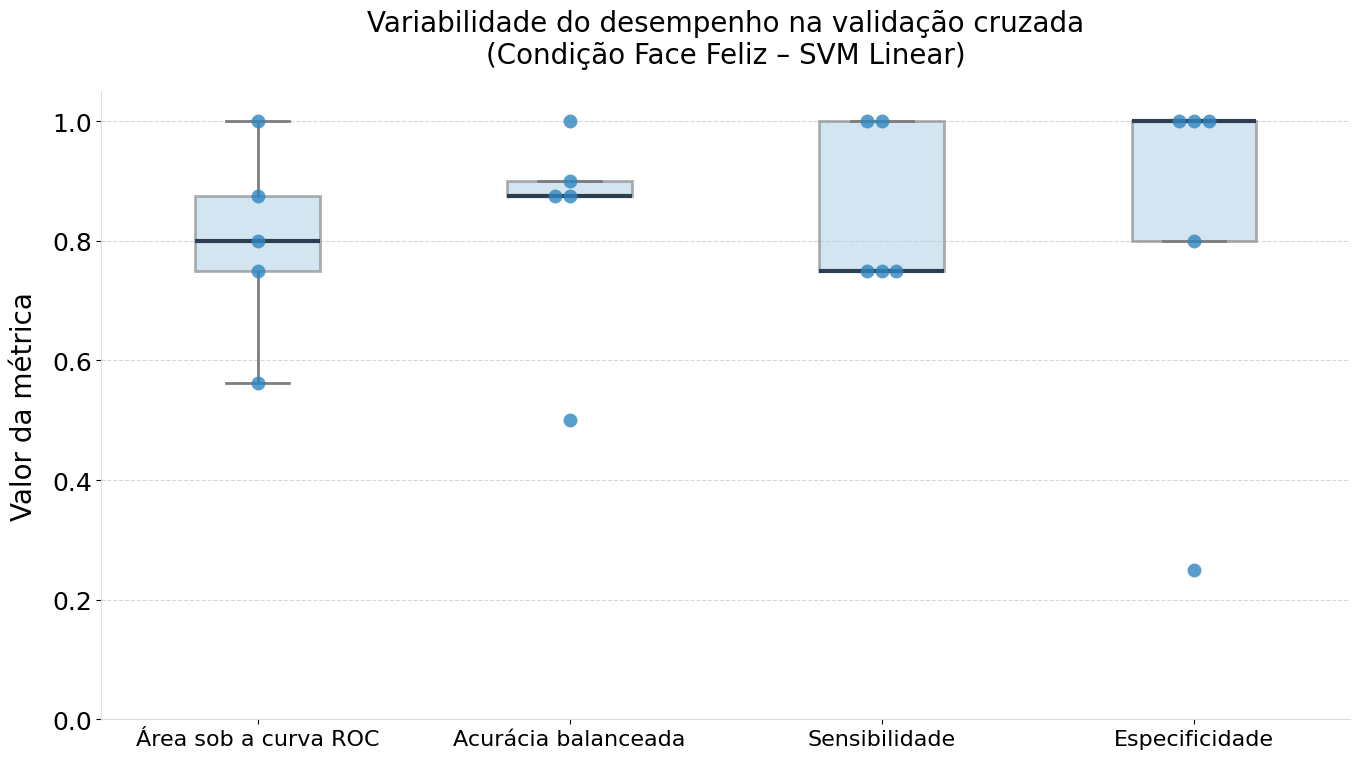


DESEMPENHO MÉDIO ± DESVIO-PADRÃO

Área sob a curva ROC: 0.7975 ± 0.1446
Acurácia balanceada: 0.8300 ± 0.1713
Sensibilidade: 0.8500 ± 0.1225
Especificidade: 0.8100 ± 0.2905

RESULTADOS EM PORCENTAGEM

Área sob a curva ROC: 79.75% (±14.46%)
Acurácia balanceada: 83.00% (±17.13%)
Sensibilidade: 85.00% (±12.25%)
Especificidade: 81.00% (±29.05%)


In [7]:

# VISUALIZAÇÃO: VARIABILIDADE DO DESEMPENHO NA VALIDAÇÃO CRUZADA (SVM LINEAR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    recall_score,
    confusion_matrix
)
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 18,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e filtragem dos dados
# Apenas Face Feliz | N = 40 participantes pareados

caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(
    numeric_only=True
).reset_index()

# Remoção dos participantes despareados/artefatos (13, 34 e 42)
ids_remover = [13, 34, 42]

df_f['ID_num'] = (
    df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
)

df_f = (
    df_f[~df_f['ID_num'].isin(ids_remover)]
    .drop(columns=['ID_num'])
    .reset_index(drop=True)
)

y = df_f['Grupo'].apply(
    lambda x: 1 if 'TEA' in x else 0
).values

# 3. Seleção das cinco variáveis
features_ouro = [
    'AlphaRel_P3',
    'AlphaRel_Fp2',
    'BetaRel_F7',
    'AlphaRel_F8',
    'GammaRel_F7'
]

X = df_f[features_ouro].values

# 4. Validação cruzada estratificada (5 folds)
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=23
)

svm_modelo = SVC(
    kernel='linear',
    class_weight='balanced',
    probability=True,
    random_state=42
)

scaler = StandardScaler()

# 5. Armazenamento das métricas em português
resultados = {
    'Área sob a curva ROC': [],
    'Acurácia balanceada': [],
    'Sensibilidade': [],
    'Especificidade': []
}

# 6. Execução da validação cruzada
for train_index, test_index in skf.split(X, y):

    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # Padronização independente em cada fold (sem vazamento de dados)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    svm_modelo.fit(X_train_scaled, y_train)

    y_pred = svm_modelo.predict(X_test_scaled)
    y_proba = svm_modelo.predict_proba(X_test_scaled)[:, 1]

    # Matriz de confusão
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Cálculo das métricas
    resultados['Área sob a curva ROC'].append(
        roc_auc_score(y_test, y_proba)
    )

    resultados['Acurácia balanceada'].append(
        balanced_accuracy_score(y_test, y_pred)
    )

    resultados['Sensibilidade'].append(
        recall_score(y_test, y_pred)
    )

    resultados['Especificidade'].append(
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

# 7. Organização dos resultados para visualização
df_metricas = pd.DataFrame(resultados)

df_melted = df_metricas.melt(
    var_name='Métrica',
    value_name='Desempenho'
)

# 8. Construção do gráfico
fig, ax = plt.subplots(figsize=(14, 8))

# Boxplot
sns.boxplot(
    data=df_melted,
    x='Métrica',
    y='Desempenho',
    color='#AED6F1',
    width=0.4,
    linewidth=2,
    boxprops=dict(alpha=0.6),
    medianprops=dict(
        color='#2C3E50',
        linewidth=3
    ),
    showfliers=False,
    ax=ax
)

# Dispersão dos resultados individuais dos folds
sns.swarmplot(
    data=df_melted,
    x='Métrica',
    y='Desempenho',
    color='#2E86C1',
    size=10,
    alpha=0.8,
    ax=ax
)

# 9. Títulos e eixos em português
ax.set_ylim(0.0, 1.05)

ax.set_title(
    'Variabilidade do desempenho na validação cruzada\n'
    '(Condição Face Feliz – SVM Linear)',
    pad=20
)

ax.set_ylabel('Valor da métrica', labelpad=10)
ax.set_xlabel('')

# Formatação dos eixos
ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.5,
    color='#B0B0B0'
)

ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')

plt.xticks(rotation=0, ha='center')

plt.tight_layout()

# 10. Salvamento da imagem
os.makedirs('../reports/figures', exist_ok=True)

caminho_imagem = (
    '../reports/figures/fig01_cv_metrics_distribution_svm.png'
)

plt.savefig(
    caminho_imagem,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

print(
    f"Imagem gerada e salva em: {caminho_imagem}"
)

plt.show()

# 11. Exibição das médias e desvios-padrão
print("\nDESEMPENHO MÉDIO ± DESVIO-PADRÃO\n")

for metrica, valores in resultados.items():

    media = np.mean(valores)
    std = np.std(valores)

    print(
        f"{metrica}: {media:.4f} ± {std:.4f}"
    )

# 12. Resultados em porcentagem para o manuscrito
print("\nRESULTADOS EM PORCENTAGEM\n")

for metrica, valores in resultados.items():

    media = np.mean(valores)
    std = np.std(valores)

    print(
        f"{metrica}: "
        f"{media * 100:.2f}% "
        f"(±{std * 100:.2f}%)"
    )


# ANTERIOR

In [4]:
# Aprendizado de Máquina (5-Fold CV)

import os
import warnings
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# 1. Carregamento e Filtragem dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# Variáveis selecionadas
features_ouro = [
    'AlphaRel_P3',
    'AlphaRel_Fp2',
    'BetaRel_F7',
    'AlphaRel_F8',
    'GammaRel_F7',
]
X = df_f[features_ouro].values

# 2. Pipeline e Validação Cruzada
pipeline = Pipeline(
    [('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

# Predição fora da amostra (Out-of-fold predictions)
y_pred = cross_val_predict(pipeline, X, y, cv=cv_strategy)

# 3. Cálculo das Métricas de Desempenho
tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()

acuracia = (tp + tn) / (tp + tn + fp + fn)
sensibilidade = tp / (tp + fn)  # Recall / Revocação / True Positive Rate
especificidade = tn / (tn + fp)  # True Negative Rate
precisao = tp / (tp + fp)  # Positive Predictive Value
f1 = 2 * (precisao * sensibilidade) / (precisao + sensibilidade)

# 4. Exibição dos Resultados 
print('=' * 45)
print('    MÉTRICAS DE DESEMPENHO (5-FOLD CV)')
print('=' * 45)
print(f'Acurácia:       {acuracia:.4f} ({acuracia * 100:.2f}%)')
print(f'Sensibilidade:  {sensibilidade:.4f} ({sensibilidade * 100:.2f}%)')
print(f'Especificidade: {especificidade:.4f} ({especificidade * 100:.2f}%)')
print(f'Precisão:       {precisao:.4f} ({precisao * 100:.2f}%)')
print(f'F1-Score:       {f1:.4f}')
print('=' * 45)

# Relatório detalhado por classe
print('\nRelatório de Classificação Detalhado:')
print(
    classification_report(
        y, y_pred, target_names=['Control (0)', 'ASD (1)'], digits=4
    )
)

    MÉTRICAS DE DESEMPENHO (5-FOLD CV)
Acurácia:       0.8571 (85.71%)
Sensibilidade:  0.8333 (83.33%)
Especificidade: 0.8750 (87.50%)
Precisão:       0.8333 (83.33%)
F1-Score:       0.8333

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

 Control (0)     0.8750    0.8750    0.8750        24
     ASD (1)     0.8333    0.8333    0.8333        18

    accuracy                         0.8571        42
   macro avg     0.8542    0.8542    0.8542        42
weighted avg     0.8571    0.8571    0.8571        42



In [1]:
# Aprendizado de Máquina (5-Fold CV - N=39, sem IDs 13, 34 e 42)

import os
import warnings
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# 1. Carregamento e Filtragem dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Filtragem de Remoção dos Participantes 13, 34 e 42 (Alinhamento Eye Tracking)
ids_remover = [13, 34, 42]

# Trata IDs tanto numéricos quanto no formato texto contendo o número (ex: 'P13', '13')
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num'])

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# Variáveis selecionadas
features_ouro = [
    'AlphaRel_P3',
    'AlphaRel_Fp2',
    'BetaRel_F7',
    'AlphaRel_F8',
    'GammaRel_F7',
]
X = df_f[features_ouro].values

# 2. Pipeline e Validação Cruzada
pipeline = Pipeline(
    [('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=42))]
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

# Predição fora da amostra (Out-of-fold predictions)
y_pred = cross_val_predict(pipeline, X, y, cv=cv_strategy)

# 3. Cálculo das Métricas de Desempenho
tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()

acuracia = (tp + tn) / (tp + tn + fp + fn)
sensibilidade = tp / (tp + fn)  # Recall / Revocação / True Positive Rate
especificidade = tn / (tn + fp)  # True Negative Rate
precisao = tp / (tp + fp)  # Positive Predictive Value
f1 = 2 * (precisao * sensibilidade) / (precisao + sensibilidade)

# 4. Exibição dos Resultados
print('=' * 45)
print(f'   MÉTRICAS DE DESEMPENHO (5-FOLD CV | N={len(df_f)})')
print('=' * 45)
print(f'Acurácia:       {acuracia:.4f} ({acuracia * 100:.2f}%)')
print(f'Sensibilidade:  {sensibilidade:.4f} ({sensibilidade * 100:.2f}%)')
print(f'Especificidade: {especificidade:.4f} ({especificidade * 100:.2f}%)')
print(f'Precisão:       {precisao:.4f} ({precisao * 100:.2f}%)')
print(f'F1-Score:       {f1:.4f}')
print('=' * 45)

# Relatório detalhado por classe
print('\nRelatório de Classificação Detalhado:')
print(
    classification_report(
        y, y_pred, target_names=['Control (0)', 'ASD (1)'], digits=4
    )
)

   MÉTRICAS DE DESEMPENHO (5-FOLD CV | N=40)
Acurácia:       0.7500 (75.00%)
Sensibilidade:  0.7778 (77.78%)
Especificidade: 0.7273 (72.73%)
Precisão:       0.7000 (70.00%)
F1-Score:       0.7368

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

 Control (0)     0.8000    0.7273    0.7619        22
     ASD (1)     0.7000    0.7778    0.7368        18

    accuracy                         0.7500        40
   macro avg     0.7500    0.7525    0.7494        40
weighted avg     0.7550    0.7500    0.7506        40



In [2]:
# Benchmarking de Modelos e Validações Cruzadas (N=39)

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import (
    StratifiedKFold, 
    LeaveOneOut, 
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

warnings.filterwarnings('ignore')

# 1. Carregamento e Filtragem dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Remoção dos Participantes 13, 34 e 42 (Alinhamento Eye Tracking)
ids_remover = [13, 34, 42]
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num'])

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

features_ouro = [
    'AlphaRel_P3',
    'AlphaRel_Fp2',
    'BetaRel_F7',
    'AlphaRel_F8',
    'GammaRel_F7',
]
X = df_f[features_ouro].values

# 2. Definição dos Classificadores a Testar
modelos = {
    'Random Forest (Padrão)': RandomForestClassifier(random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(class_weight='balanced', random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'SVM (RBF - Balanced)': SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42),
    'SVM (Linear)': SVC(kernel='linear', class_weight='balanced', random_state=42),
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric='logloss', random_state=42),
    'KNN (k=3)': KNeighborsClassifier(n_neighbors=3),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

# 3. Definição das Estratégias de Validação Cruzada
estrategias_cv = {
    '5-Fold': StratifiedKFold(n_splits=5, shuffle=True, random_state=23),
    '10-Fold': StratifiedKFold(n_splits=10, shuffle=True, random_state=23),
    'LOOCV': LeaveOneOut()
}

# 4. Execução em Lote (Grid Search Rápido)
resultados = []

for nome_cv, cv in estrategias_cv.items():
    for nome_modelo, clf in modelos.items():
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', clf)
        ])
        
        # Predição cega fora da amostra
        y_pred = cross_val_predict(pipeline, X, y, cv=cv, n_jobs=-1)
        
        # Cálculo das Métricas
        tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
        
        acuracia = (tp + tn) / (tp + tn + fp + fn)
        sensibilidade = tp / (tp + fn) if (tp + fn) > 0 else 0
        especificidade = tn / (tn + fp) if (tn + fp) > 0 else 0
        precisao = tp / (tp + fp) if (tp + fp) > 0 else 0
        f1 = 2 * (precisao * sensibilidade) / (precisao + sensibilidade) if (precisao + sensibilidade) > 0 else 0
        
        resultados.append({
            'Modelo': nome_modelo,
            'Validação': nome_cv,
            'Acurácia': acuracia,
            'Sensibilidade': sensibilidade,
            'Especificidade': especificidade,
            'Precisão': precisao,
            'F1-Score': f1,
            'TP/FN': f'{tp}/{fn}',
            'TN/FP': f'{tn}/{fp}'
        })

# 5. Organização e Exibição do Ranking de Resultados
df_res = pd.DataFrame(resultados)

# Ordena por Sensibilidade primeiro (seu foco principal), depois por Acurácia
df_res = df_res.sort_values(by=['Sensibilidade', 'Acurácia'], ascending=[False, False]).reset_index(drop=True)

print('=' * 85)
print(f'   EXPLORAÇÃO DE MODELOS E VALIDAÇÕES (N={len(df_f)} PARTICIPANTES)')
print('=' * 85)
print(df_res.to_string(index=False, formatters={
    'Acurácia': '{:.2%}'.format,
    'Sensibilidade': '{:.2%}'.format,
    'Especificidade': '{:.2%}'.format,
    'Precisão': '{:.2%}'.format,
    'F1-Score': '{:.4f}'.format
}))
print('=' * 85)

# Destaque do Melhor Modelo
melhor = df_res.iloc[0]
print(f"\n🏆 MELHOR CONFIGURAÇÃO PARA SENSIBILIDADE:")
print(f"Modelo:       {melhor['Modelo']}")
print(f"Validação:    {melhor['Validação']}")
print(f"Sensibilidade:{melhor['Sensibilidade']:.2%}")
print(f"Acurácia:     {melhor['Acurácia']:.2%}")

   EXPLORAÇÃO DE MODELOS E VALIDAÇÕES (N=40 PARTICIPANTES)
                  Modelo Validação Acurácia Sensibilidade Especificidade Precisão F1-Score TP/FN TN/FP
            SVM (Linear)    5-Fold   82.50%        83.33%         81.82%   78.95%   0.8108  15/3  18/4
                 XGBoost    5-Fold   82.50%        83.33%         81.82%   78.95%   0.8108  15/3  18/4
     Logistic Regression    5-Fold   80.00%        77.78%         81.82%   77.78%   0.7778  14/4  18/4
  Random Forest (Padrão)   10-Fold   80.00%        77.78%         81.82%   77.78%   0.7778  14/4  18/4
Random Forest (Balanced)   10-Fold   80.00%        77.78%         81.82%   77.78%   0.7778  14/4  18/4
    SVM (RBF - Balanced)     LOOCV   80.00%        77.78%         81.82%   77.78%   0.7778  14/4  18/4
Random Forest (Balanced)    5-Fold   77.50%        77.78%         77.27%   73.68%   0.7568  14/4  17/5
    SVM (RBF - Balanced)    5-Fold   77.50%        77.78%         77.27%   73.68%   0.7568  14/4  17/5
    SVM (RBF -

In [3]:
# 1. Carregamento e Filtragem dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

print(f"📊 Total de participantes na base original ('Face Feliz'): {len(df_f)}")

# Lista de IDs a remover
ids_remover = [13, 34, 42]

# Extrai o número do ID para comparação
df_f['ID_num'] = df_f['ID'].astype(str).str.extract(r'(\d+)').astype(float)

# Diagnóstico de remoção
encontrados = df_f[df_f['ID_num'].isin(ids_remover)]['ID'].tolist()
print(f"🔍 IDs identificados para remoção: {encontrados}")

# Aplica a remoção
df_f = df_f[~df_f['ID_num'].isin(ids_remover)].drop(columns=['ID_num']).reset_index(drop=True)

print(f"✅ Total final de participantes para o modelo: N = {len(df_f)}")

📊 Total de participantes na base original ('Face Feliz'): 42
🔍 IDs identificados para remoção: ['control_13_faces', 'control_42_faces']
✅ Total final de participantes para o modelo: N = 40


# 05. Plots

✅ Matriz de Confusão gerada e salva em: ../reports/figures/fig01_confusion_matrix_rf.png


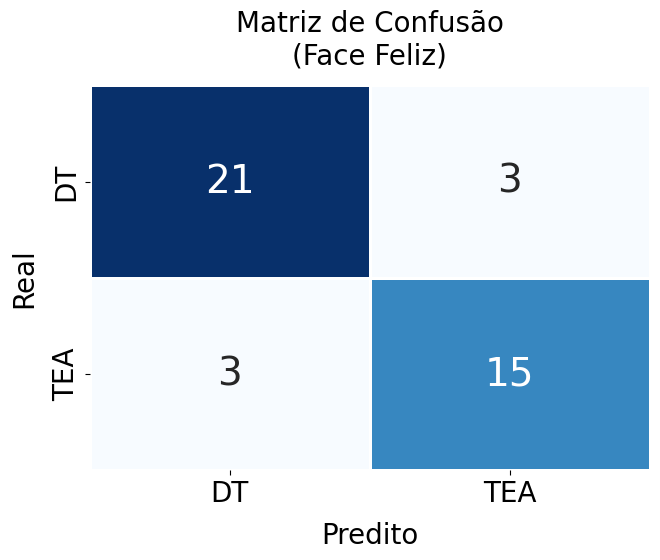

In [9]:
# 02. VISUALIZAÇÃO: MATRIZ DE CONFUSÃO (RANDOM FOREST 5-FOLD CV)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis de Ouro
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Pipeline final (StandardScaler + Random Forest)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])

# Validação Rigorosa
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

# 4. Preparação do Plot
fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('white')

# Predição com 5-Fold CV
y_pred = cross_val_predict(pipeline, X, y, cv=cv_strategy)
cm = confusion_matrix(y, y_pred)

# Plotagem
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['DT', 'TEA'], yticklabels=['DT', 'TEA'],
            annot_kws={"size": 28, "weight": "normal"}, 
            linewidths=2, linecolor='white')

ax.set_title('Matriz de Confusão\n(Face Feliz)', pad=15)
ax.set_ylabel('Real', labelpad=10)
ax.set_xlabel('Predito', labelpad=10)

plt.tight_layout()

os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig01_confusion_matrix_rf.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Matriz de Confusão gerada e salva em: {caminho_imagem}")
plt.show()

✅ Matriz de Confusão gerada e salva em: ../reports/figures/fig01_confusion_matrix_rf.png


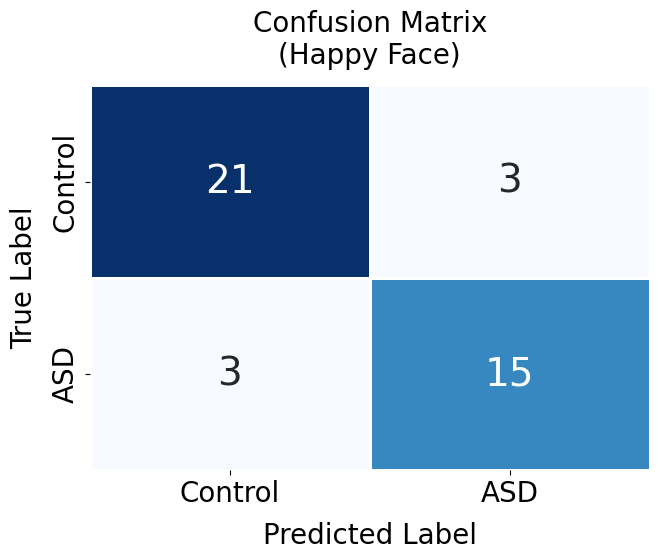

In [2]:
# 02. VISUALIZAÇÃO: MATRIZ DE CONFUSÃO (RANDOM FOREST 5-FOLD CV)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis de Ouro
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Pipeline final (StandardScaler + Random Forest)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])

# Validação Rigorosa
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

# 4. Preparação do Plot
fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('white')

# Predição com 5-Fold CV
y_pred = cross_val_predict(pipeline, X, y, cv=cv_strategy)
cm = confusion_matrix(y, y_pred)

# Plotagem
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'],
            annot_kws={"size": 28, "weight": "normal"}, 
            linewidths=2, linecolor='white')

ax.set_title('Confusion Matrix\n(Happy Face)', pad=15)
ax.set_ylabel('True Label', labelpad=10)
ax.set_xlabel('Predicted Label', labelpad=10)

plt.tight_layout()

os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig01_confusion_matrix_rf.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Matriz de Confusão gerada e salva em: {caminho_imagem}")
plt.show()

✅ Feature Importance gerada e salva em: ../reports/figures/fig02_feature_importance_rf.png


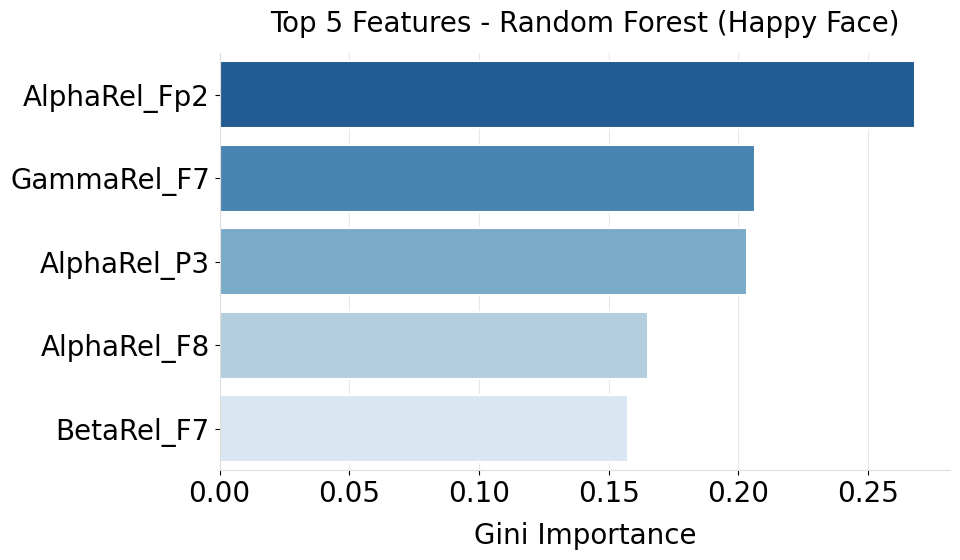

In [ ]:
# 03. VISUALIZAÇÃO: FEATURE IMPORTANCE (RANDOM FOREST)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais 
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento de Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X_sel = df_f[features_ouro]

# Treinamento do Random Forest Base
rf_modelo = RandomForestClassifier(random_state=42)
rf_modelo.fit(X_sel, y)

# 3. Extração (Gini Importance)
importancias = rf_modelo.feature_importances_
df_imp = pd.DataFrame({
    'Feature': features_ouro,
    'Importance': importancias
}).sort_values(by='Importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_axisbelow(True)

sns.barplot(data=df_imp, x='Importance', y='Feature', palette='Blues_r', edgecolor='white', linewidth=1.5, ax=ax)

# Ajustes de título e legenda
ax.set_title('Top 5 Features - Random Forest (Happy Face)', pad=15)
ax.set_xlabel('Gini Importance', labelpad=10)
ax.set_ylabel('')

ax.grid(axis='x', linestyle='-', alpha=0.3, color='#B0B0B0')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')

plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig02_feature_importance_rf.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Feature Importance gerada e salva em: {caminho_imagem}")
plt.show()

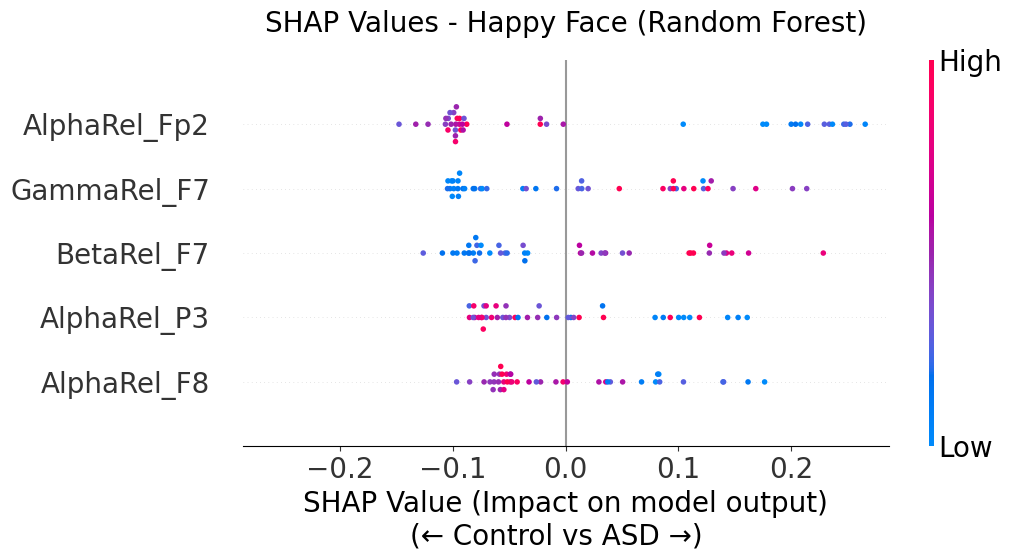

✅ SHAP Values gerados e salvos em: ../reports/figures/fig03_shap_values_rf.png


In [ ]:
# 04. VISUALIZAÇÃO: SHAP VALUES (RANDOM FOREST) 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import os
import warnings

try:
    import shap
except ImportError:
    print("⚠️ A biblioteca 'shap' não está instalada. Execute '!pip install shap' e rode novamente.")
    shap = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento de Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X_sel = df_f[features_ouro]

# Treinamento
rf_modelo = RandomForestClassifier(random_state=42)
rf_modelo.fit(X_sel, y)

# 3. SHAP Values
if shap is not None:
    # AJUSTE 1: Proporção (Largura, Altura) da figura base
    fig = plt.figure(figsize=(11, 6))
    
    explainer = shap.TreeExplainer(rf_modelo)
    shap_values = explainer.shap_values(X_sel)
    
    if isinstance(shap_values, list):
        shap_values_tea = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
        shap_values_tea = shap_values[:, :, 1]
    else:
        shap_values_tea = shap_values

    plt.title('SHAP Values - Happy Face (SVM)', pad=20, fontsize=20)
    
    # AJUSTE 2: O parâmetro plot_size=(Largura, Altura) força o SHAP a respeitar a proporção
    shap.summary_plot(shap_values_tea, X_sel, feature_names=features_ouro, show=False, plot_size=(11, 6))
    
    # Centralização do eixo x
    ax = plt.gca()
    limites_x = ax.get_xlim()
    max_abs = max(abs(limites_x[0]), abs(limites_x[1]))
    ax.set_xlim(-max_abs, max_abs) 
    
    ax.set_xlabel('SHAP Value (Impact on model output)\n(← Control vs ASD →)  ', fontsize=20, fontweight='normal')
    ax.tick_params(axis='both', labelsize=20)
    
    # Ajuste dos rótulos do eixo Y (Colorbar)
    fig = plt.gcf()
    for eixo in fig.axes:
        if eixo != ax: 
            eixo.set_ylabel('') 
            eixo.set_yticks([0, 1])
            eixo.set_yticklabels(['Low', 'High'], fontsize=20, fontweight='normal')
            eixo.tick_params(length=0) 
    
    plt.tight_layout()
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_fig = '../reports/figures/fig03_shap_values_rf.png'
    plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ SHAP Values gerados e salvos em: {caminho_fig}")

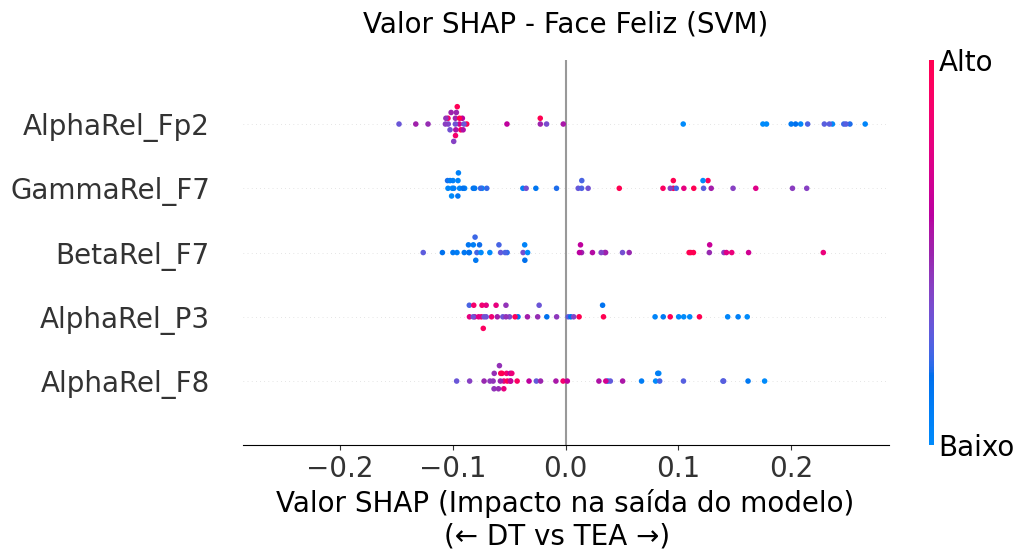

✅ SHAP Values gerados e salvos em: ../reports/figures/fig03_shap_values_rf.png


In [10]:
# 04. VISUALIZAÇÃO: SHAP VALUES (RANDOM FOREST) 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import os
import warnings

try:
    import shap
except ImportError:
    print("⚠️ A biblioteca 'shap' não está instalada. Execute '!pip install shap' e rode novamente.")
    shap = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento de Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X_sel = df_f[features_ouro]

# Treinamento
rf_modelo = RandomForestClassifier(random_state=42)
rf_modelo.fit(X_sel, y)

# 3. SHAP Values
if shap is not None:
    # AJUSTE 1: Proporção (Largura, Altura) da figura base
    fig = plt.figure(figsize=(11, 6))
    
    explainer = shap.TreeExplainer(rf_modelo)
    shap_values = explainer.shap_values(X_sel)
    
    if isinstance(shap_values, list):
        shap_values_tea = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
        shap_values_tea = shap_values[:, :, 1]
    else:
        shap_values_tea = shap_values

    plt.title('Valor SHAP - Face Feliz (SVM)', pad=20, fontsize=20)
    
    # AJUSTE 2: O parâmetro plot_size=(Largura, Altura) força o SHAP a respeitar a proporção
    shap.summary_plot(shap_values_tea, X_sel, feature_names=features_ouro, show=False, plot_size=(11, 6))
    
    # Centralização do eixo x
    ax = plt.gca()
    limites_x = ax.get_xlim()
    max_abs = max(abs(limites_x[0]), abs(limites_x[1]))
    ax.set_xlim(-max_abs, max_abs) 
    
    ax.set_xlabel('Valor SHAP (Impacto na saída do modelo)\n(← DT vs TEA →)  ', fontsize=20, fontweight='normal')
    ax.tick_params(axis='both', labelsize=20)
    
    # Ajuste dos rótulos do eixo Y (Colorbar)
    fig = plt.gcf()
    for eixo in fig.axes:
        if eixo != ax: 
            eixo.set_ylabel('') 
            eixo.set_yticks([0, 1])
            eixo.set_yticklabels(['Baixo', 'Alto'], fontsize=20, fontweight='normal')
            eixo.tick_params(length=0) 
    
    plt.tight_layout()
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_fig = '../reports/figures/fig03_shap_values_rf.png'
    plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ SHAP Values gerados e salvos em: {caminho_fig}")

✅ Distribuição de Métricas gerada e salva em: ../reports/figures/fig01_cv_metrics_distribution.png


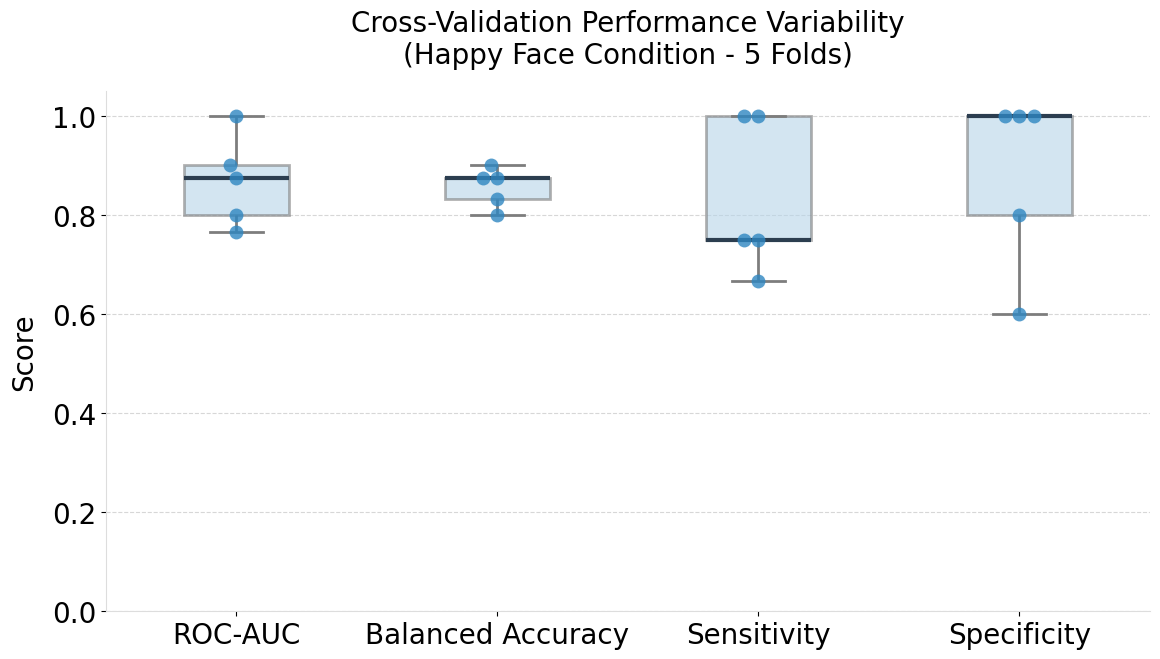


Mean Performance ± Standard Deviation:
ROC-AUC: 0.8683 ± 0.0817
Balanced Accuracy: 0.8567 ± 0.0355
Sensitivity: 0.8333 ± 0.1394
Specificity: 0.8800 ± 0.1600


In [ ]:
# 05. VISUALIZAÇÃO: CROSS-VALIDATION PERFORMANCE VARIABILITY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, recall_score, confusion_matrix
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis Selecionadas 
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Extração Rigorosa de Métricas (5-Fold CV)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
rf_modelo = RandomForestClassifier(random_state=42)
scaler = StandardScaler()

# Nomenclatura com padronização correta (Title Case)
resultados = {
    'ROC-AUC': [],
    'Balanced Accuracy': [],
    'Sensitivity': [],
    'Specificity': []
}

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Transformação estrita no fold (Leakage-free)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    rf_modelo.fit(X_train_scaled, y_train)
    y_pred = rf_modelo.predict(X_test_scaled)
    y_proba = rf_modelo.predict_proba(X_test_scaled)[:, 1]
    
    # Cálculos das métricas
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    
    resultados['ROC-AUC'].append(roc_auc_score(y_test, y_proba))
    resultados['Balanced Accuracy'].append(balanced_accuracy_score(y_test, y_pred))
    resultados['Sensitivity'].append(recall_score(y_test, y_pred)) # TPR
    resultados['Specificity'].append(tn / (tn + fp)) # TNR

# Formatação em DataFrame para o Seaborn
df_metricas = pd.DataFrame(resultados)
df_melted = df_metricas.melt(var_name='Metric', value_name='Score')

# 4. Preparação do Plot
fig, ax = plt.subplots(figsize=(12, 7))

# Boxplot com linha da mediana destacada
sns.boxplot(data=df_melted, x='Metric', y='Score', 
            color='#AED6F1', width=0.4, linewidth=2, 
            boxprops=dict(alpha=0.6), 
            medianprops=dict(color='#2C3E50', linewidth=3), # Mediana mais escura e grossa
            showfliers=False, ax=ax)

# Swarmplot para espalhar os pontos sem sobreposição vertical
sns.swarmplot(data=df_melted, x='Metric', y='Score', 
              color='#2E86C1', size=10, alpha=0.8, ax=ax)

# Ajustes de Eixos e Títulos com padrão gramatical inglês acadêmico
ax.set_ylim(0.0, 1.05)
ax.set_title('Cross-Validation Performance Variability\n(Happy Face Condition - 5 Folds)', pad=20)
ax.set_ylabel('Score', labelpad=10)
ax.set_xlabel('')

# Estética limpa
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#B0B0B0')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')

plt.tight_layout()

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig01_cv_metrics_distribution.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Distribuição de Métricas gerada e salva em: {caminho_imagem}")
plt.show()

# Exibição de texto para relatório
print("\nMean Performance ± Standard Deviation:")
for metrica in resultados.keys():
    media = np.mean(resultados[metrica])
    std = np.std(resultados[metrica])
    print(f"{metrica}: {media:.4f} ± {std:.4f}")

✅ Matriz de Confusão e Curva ROC geradas e salvas em: ../reports/figures/fig02_classification_evaluation.png


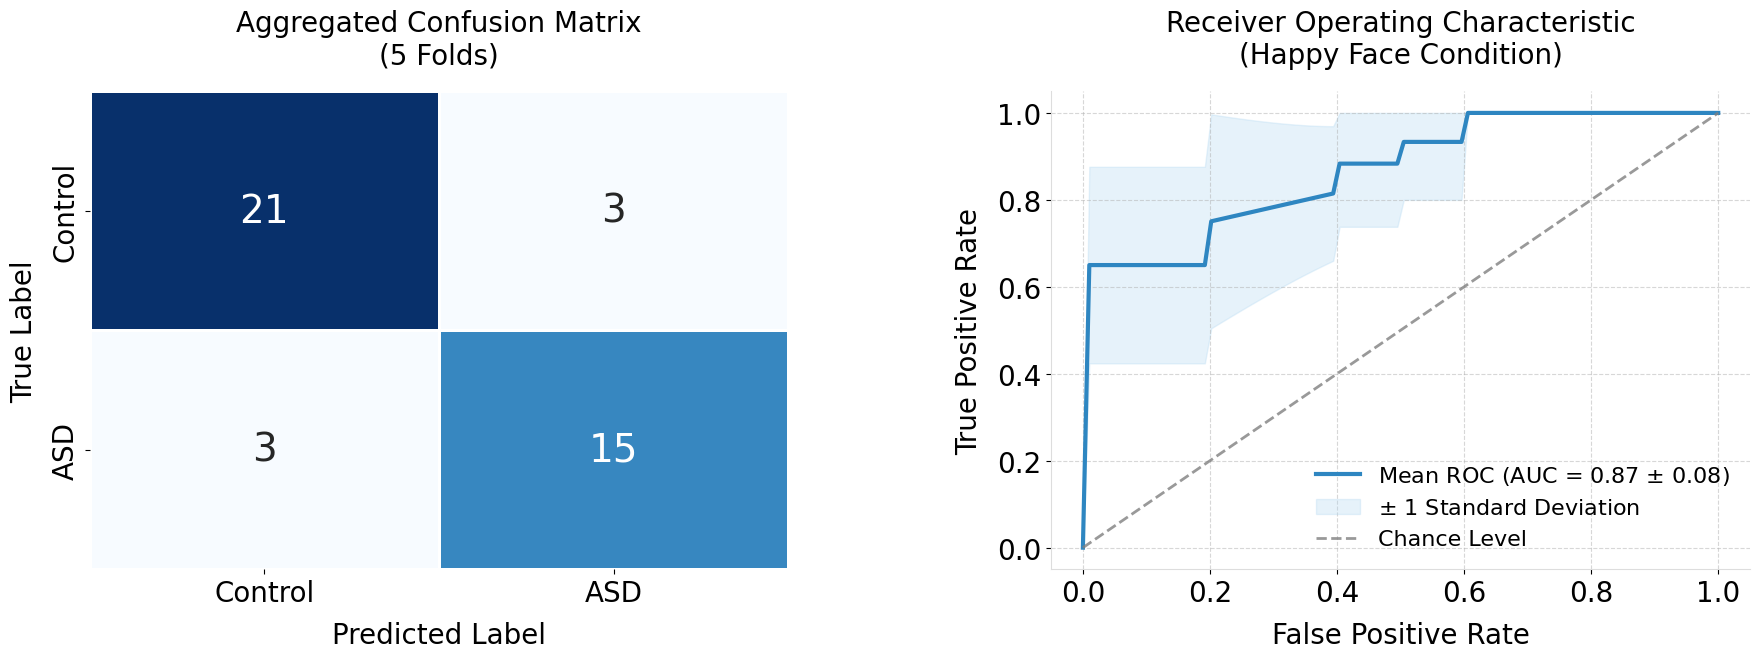

In [ ]:
# 06. VISUALIZAÇÃO: CLASSIFICATION EVALUATION (CM + MEAN ROC CURVE)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc
import warnings
import os

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis Selecionadas (ANOVA)
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X = df_f[features_ouro].values

# 3. Treinamento Rigoroso e Extração para ROC/CM
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
rf_modelo = RandomForestClassifier(random_state=42)
scaler = StandardScaler()

tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)
y_pred_all = []
y_true_all = []

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    # Transformação estrita no fold (Leakage-free)
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    rf_modelo.fit(X_train_scaled, y_train)
    y_proba = rf_modelo.predict_proba(X_test_scaled)[:, 1]
    y_pred = rf_modelo.predict(X_test_scaled)
    
    # Armazenamento para a Matriz de Confusão Agregada
    y_true_all.extend(y_test)
    y_pred_all.extend(y_pred)
    
    # Cálculos para a Curva ROC do fold atual
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    
    # Interpolação para padronizar o eixo X (FPR) e poder calcular a média da curva
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

# 4. Preparação do Plot (1 linha, 2 colunas)
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- PLOT 1: Matriz de Confusão Agregada ---
cm = confusion_matrix(y_true_all, y_pred_all)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'],
            annot_kws={"size": 28, "weight": "normal"}, 
            linewidths=2, linecolor='white')

axes[0].set_title('Aggregated Confusion Matrix\n(5 Folds)', pad=20)
axes[0].set_ylabel('True Label', labelpad=10)
axes[0].set_xlabel('Predicted Label', labelpad=10)

# --- PLOT 2: Mean ROC Curve ---
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

# Sombreamento do Desvio Padrão
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)

axes[1].plot(mean_fpr, mean_tpr, color='#2E86C1', linewidth=3,
             label=f'Mean ROC (AUC = {mean_auc:.2f} $\pm$ {std_auc:.2f})')
axes[1].fill_between(mean_fpr, tprs_lower, tprs_upper, color='#AED6F1', alpha=0.3,
                     label=r'$\pm$ 1 Standard Deviation')

# Linha de Chance (50%)
axes[1].plot([0, 1], [0, 1], linestyle='--', lw=2, color='gray', label='Chance Level', alpha=0.8)

# Ajustes de Eixos e Títulos da Curva ROC
axes[1].set_xlim([-0.05, 1.05])
axes[1].set_ylim([-0.05, 1.05])
axes[1].set_xlabel('False Positive Rate', labelpad=10)
axes[1].set_ylabel('True Positive Rate', labelpad=10)
axes[1].set_title('Receiver Operating Characteristic\n(Happy Face Condition)', pad=20)
axes[1].legend(loc="lower right", fontsize=16, frameon=False)

axes[1].grid(axis='both', linestyle='--', alpha=0.5, color='#B0B0B0')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].spines['left'].set_color('#DDDDDD')
axes[1].spines['bottom'].set_color('#DDDDDD')

plt.tight_layout(w_pad=6.0)

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_imagem = '../reports/figures/fig02_classification_evaluation.png'
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
print(f"✅ Matriz de Confusão e Curva ROC geradas e salvas em: {caminho_imagem}")
plt.show()

Valor Máximo de Cohen's d encontrado (deve ser diferente de 0): 1.1208


✅ Topomaps de Tamanho de Efeito gerados e salvos em: ../reports/figures/fig03_cohens_d_topomaps.png


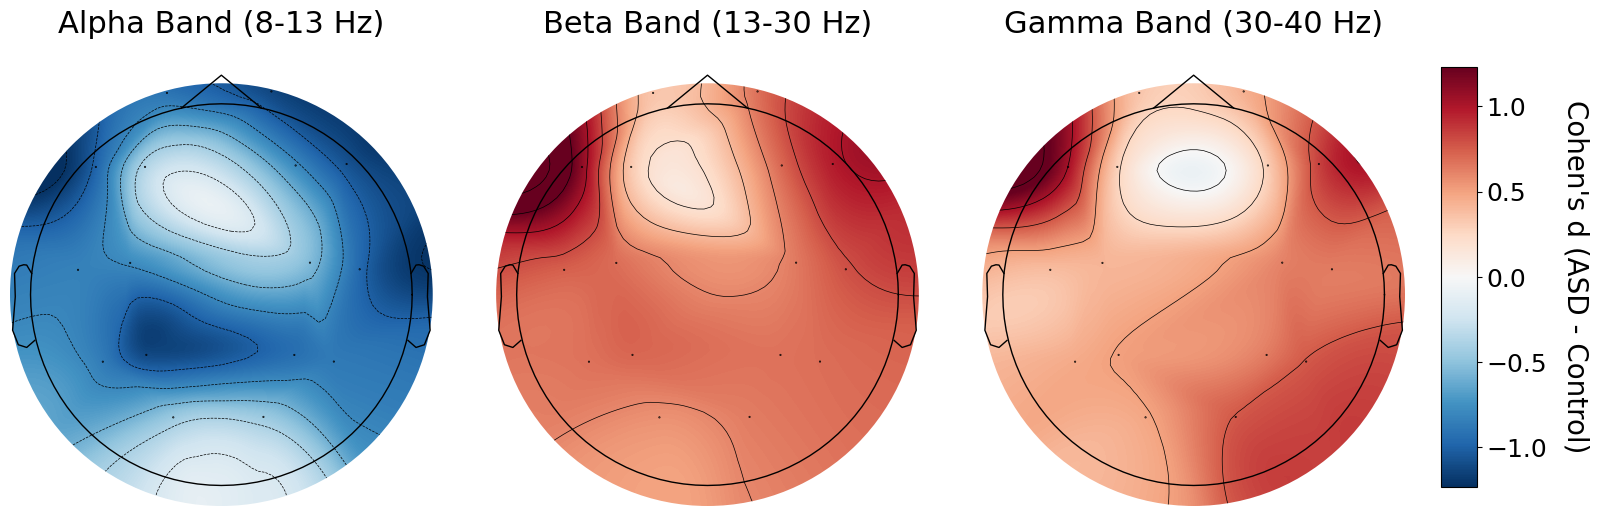

In [ ]:
# 07. VISUALIZAÇÃO: GROUP-LEVEL EEG DIFFERENCES (COHEN'S D TOPOMAPS)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

try:
    import mne
except ImportError:
    print("⚠️ A biblioteca 'mne' não está instalada. Execute '!pip install mne' e rode novamente.")
    mne = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 22,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Função de cálculo (Cohen's d)
def calcular_cohens_d(grupo1, grupo2):
    g1 = pd.to_numeric(grupo1, errors='coerce').dropna()
    g2 = pd.to_numeric(grupo2, errors='coerce').dropna()
    
    # Proteção caso o canal esteja vazio
    if len(g1) < 2 or len(g2) < 2:
        return 0.0  
        
    n1, n2 = len(g1), len(g2)
    var1, var2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    s_pooled = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    d = (np.mean(g1) - np.mean(g2)) / s_pooled
    return d

# 3. Carregamento e Isolamento Garantido dos Grupos (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Garantia absoluta da divisão: usando o mesmo vetor y do Machine Learning
y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

df_tea = df_f[y == 1]
df_ctrl = df_f[y == 0]

# 4. Definição das Bandas e Extração dos Canais Disponíveis
bandas = ['Alpha', 'Beta', 'Gamma']
titulos = ['Alpha Band (8-13 Hz)', 'Beta Band (13-30 Hz)', 'Gamma Band (30-40 Hz)']

canais = [col.split('_')[1] for col in df_f.columns if col.startswith('AlphaRel_')]

if mne is not None:
    # Estrutura MNE Padrão 10-20
    info = mne.create_info(ch_names=canais, sfreq=1000, ch_types='eeg')
    montage = mne.channels.make_standard_montage('standard_1020')
    info.set_montage(montage)

    d_values_por_banda = []
    max_d_abs = 0  

    for banda in bandas:
        d_vals = []
        for canal in canais:
            feature_name = f'{banda}Rel_{canal}'
            d = calcular_cohens_d(df_tea[feature_name], df_ctrl[feature_name])
            d_vals.append(d)
        
        d_values_por_banda.append(np.array(d_vals))
        max_d_abs = max(max_d_abs, np.max(np.abs(d_vals)))

    print(f"Valor Máximo de Cohen's d encontrado (deve ser diferente de 0): {max_d_abs:.4f}")

    # 5. Preparação do Plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    vmax = max_d_abs * 1.1 
    vmin = -vmax
    
    # Trava de segurança (não deve mais ser ativada)
    if vmax == 0: 
        vmax, vmin = 1.0, -1.0

    for idx, (banda, ax, d_vals, titulo) in enumerate(zip(bandas, axes, d_values_por_banda, titulos)):
        # Contido estritamente na cabeça (extrapolate='head') e interpolando as cores
        im, _ = mne.viz.plot_topomap(d_vals, info, axes=ax, show=False, 
                                     cmap='RdBu_r', vlim=(vmin, vmax),
                                     extrapolate='head', contours=6)
        ax.set_title(titulo, pad=15)

    # 6. Colorbar Unificada
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) 
    cbar = plt.colorbar(im, cax=cbar_ax)
    cbar.set_label("Cohen's d (ASD - Control)", rotation=270, labelpad=30, fontsize=20)
    cbar.ax.tick_params(labelsize=18)

    plt.subplots_adjust(wspace=0.15, right=0.9)

    # 7. Salvamento
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_imagem = '../reports/figures/fig03_cohens_d_topomaps.png'
    plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
    print(f"✅ Topomaps de Tamanho de Efeito gerados e salvos em: {caminho_imagem}")
    plt.show()

✅ Painel 3x3 de Topomaps gerado e salvo em: ../reports/figures/fig03_comprehensive_topomaps_3x3.png


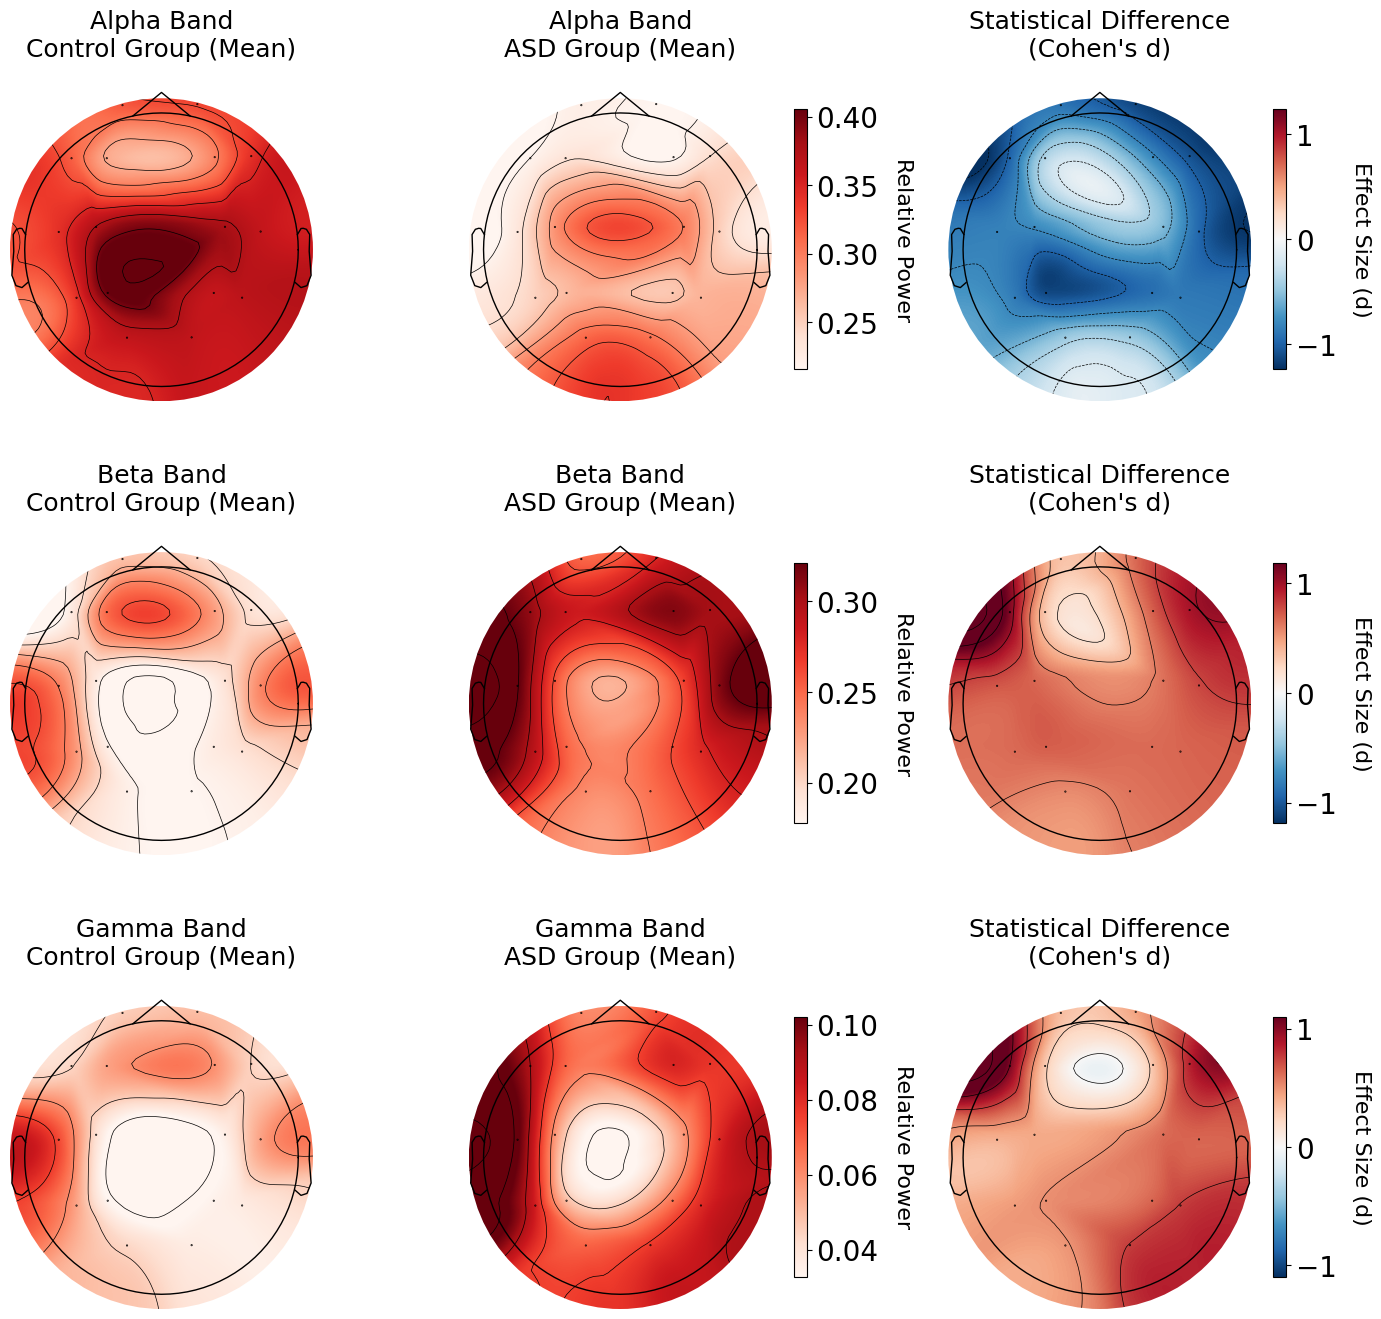

In [ ]:
# 08. VISUALIZAÇÃO ALTERNATIVA: COMPREHENSIVE EEG DIFFERENCES (3x3 GRID)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

try:
    import mne
except ImportError:
    print("⚠️ A biblioteca 'mne' não está instalada. Execute '!pip install mne' e rode novamente.")
    mne = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Função de cálculo do Cohen's d (Segura contra NaNs)
def calcular_cohens_d(grupo1, grupo2):
    g1 = pd.to_numeric(grupo1, errors='coerce').dropna()
    g2 = pd.to_numeric(grupo2, errors='coerce').dropna()
    
    if len(g1) < 2 or len(g2) < 2:
        return 0.0  
        
    n1, n2 = len(g1), len(g2)
    var1, var2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    s_pooled = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    d = (np.mean(g1) - np.mean(g2)) / s_pooled
    return d

# Função para calcular média segura contra NaNs
def calcular_media_segura(grupo):
    g = pd.to_numeric(grupo, errors='coerce').dropna()
    return np.mean(g) if len(g) > 0 else 0.0

# 3. Carregamento e Isolamento (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

df_tea = df_f[y == 1]
df_ctrl = df_f[y == 0]

# 4. Configuração das Bandas
bandas = ['Alpha', 'Beta', 'Gamma']
canais = [col.split('_')[1] for col in df_f.columns if col.startswith('AlphaRel_')]

if mne is not None:
    # Estrutura MNE Padrão 10-20
    info = mne.create_info(ch_names=canais, sfreq=1000, ch_types='eeg')
    montage = mne.channels.make_standard_montage('standard_1020')
    info.set_montage(montage)

    # 5. Preparação da Grade de Plotagem (3 linhas x 3 colunas)
    fig, axes = plt.subplots(3, 3, figsize=(18, 16))
    
    for i, banda in enumerate(bandas):
        medias_ctrl = []
        medias_tea = []
        d_vals = []
        
        # Extração dos dados por canal para a banda atual
        for canal in canais:
            feature_name = f'{banda}Rel_{canal}'
            
            m_ctrl = calcular_media_segura(df_ctrl[feature_name])
            m_tea = calcular_media_segura(df_tea[feature_name])
            d = calcular_cohens_d(df_tea[feature_name], df_ctrl[feature_name])
            
            medias_ctrl.append(m_ctrl)
            medias_tea.append(m_tea)
            d_vals.append(d)
            
        medias_ctrl = np.array(medias_ctrl)
        medias_tea = np.array(medias_tea)
        d_vals = np.array(d_vals)
        
        # Escala compartilhada de Potência Relativa (mínimo e máximo entre ambos os grupos)
        vmin_pwr = min(np.min(medias_ctrl), np.min(medias_tea))
        vmax_pwr = max(np.max(medias_ctrl), np.max(medias_tea))
        
        # Escala simétrica para o Cohen's d divergente
        vmax_d = np.max(np.abs(d_vals)) * 1.1
        vmin_d = -vmax_d if vmax_d > 0 else -1.0
        vmax_d = vmax_d if vmax_d > 0 else 1.0

        # --- COLUNA 1: Grupo Controle (Média) ---
        im_ctrl, _ = mne.viz.plot_topomap(medias_ctrl, info, axes=axes[i, 0], show=False, 
                                          cmap='Reds', vlim=(vmin_pwr, vmax_pwr),
                                          extrapolate='head', contours=6)
        axes[i, 0].set_title(f'{banda} Band\nControl Group (Mean)', pad=15)

        # --- COLUNA 2: Grupo TEA (Média) ---
        im_tea, _ = mne.viz.plot_topomap(medias_tea, info, axes=axes[i, 1], show=False, 
                                         cmap='Reds', vlim=(vmin_pwr, vmax_pwr),
                                         extrapolate='head', contours=6)
        axes[i, 1].set_title(f'{banda} Band\nASD Group (Mean)', pad=15)
        
        # Barra de Cores para a Potência Relativa (Ao lado da Coluna 2)
        cbar1 = fig.colorbar(im_tea, ax=axes[i, 1], shrink=0.8, pad=0.05)
        cbar1.set_label('Relative Power', rotation=270, labelpad=25)

        # --- COLUNA 3: Diferença Estatística (Cohen's d) ---
        im_d, _ = mne.viz.plot_topomap(d_vals, info, axes=axes[i, 2], show=False, 
                                       cmap='RdBu_r', vlim=(vmin_d, vmax_d),
                                       extrapolate='head', contours=6)
        axes[i, 2].set_title(f'Statistical Difference\n(Cohen\'s d)', pad=15)
        
        # Barra de Cores para o Cohen's d (Ao lado da Coluna 3)
        cbar2 = fig.colorbar(im_d, ax=axes[i, 2], shrink=0.8, pad=0.05)
        cbar2.set_label('Effect Size (d)', rotation=270, labelpad=25)

    # Ajustes finais de espaçamento da grade
    plt.subplots_adjust(hspace=0.4, wspace=0.1)

    # 6. Salvamento
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_imagem = '../reports/figures/fig03_comprehensive_topomaps_3x3.png'
    plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
    print(f"✅ Painel 3x3 de Topomaps gerado e salvo em: {caminho_imagem}")
    plt.show()

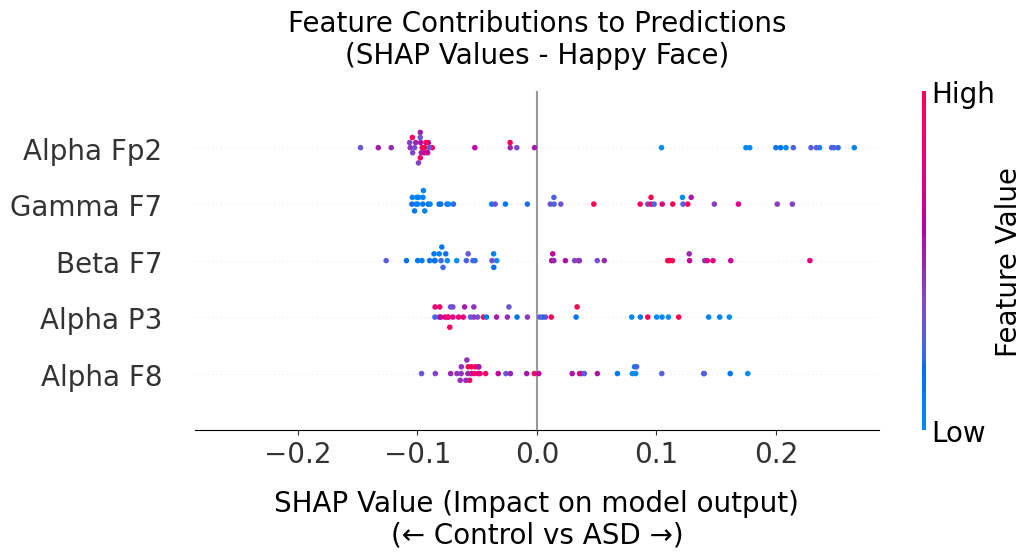

✅ SHAP Values com nomenclatura polida gerados e salvos em: ../reports/figures/fig04_shap_summary.png


In [ ]:
# 09. VISUALIZAÇÃO: EXPLAINABILITY (SHAP SUMMARY PLOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import os
import warnings

try:
    import shap
except ImportError:
    print("⚠️ A biblioteca 'shap' não está instalada. Execute '!pip install shap' e rode novamente.")
    shap = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais (Forçando 'normal' em tudo)
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal', 
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis Selecionadas 
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X_sel = df_f[features_ouro]

# LIMPEZA DE NOMES: Trocando 'AlphaRel_P3' por 'Alpha P3' (Como o humano lê)
nomes_limpos = [nome.replace('Rel_', ' ') for nome in features_ouro]

# 3. Treinamento Base
rf_modelo = RandomForestClassifier(random_state=42)
rf_modelo.fit(X_sel, y)

# 4. SHAP Values
if shap is not None:
    # Proporção equilibrada para 5 variáveis
    fig = plt.figure(figsize=(11, 6))
    
    explainer = shap.TreeExplainer(rf_modelo)
    shap_values = explainer.shap_values(X_sel)
    
    # Tratamento de compatibilidade de versão do SHAP
    if isinstance(shap_values, list):
        shap_values_tea = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
        shap_values_tea = shap_values[:, :, 1]
    else:
        shap_values_tea = shap_values

    # Injetando a lista de 'nomes_limpos' no argumento feature_names
    shap.summary_plot(shap_values_tea, X_sel, feature_names=nomes_limpos, show=False, plot_size=(11, 6))
    
    # Customização do Título e Eixos
    plt.title('Feature Contributions to Predictions\n(SHAP Values - Happy Face)', pad=20, fontsize=20, fontweight='normal')
    
    ax = plt.gca()
    
    # Centralização do eixo x (0 no meio do gráfico)
    limites_x = ax.get_xlim()
    max_abs = max(abs(limites_x[0]), abs(limites_x[1]))
    ax.set_xlim(-max_abs, max_abs) 
    
    ax.set_xlabel('SHAP Value (Impact on model output)\n(← Control vs ASD →)', fontsize=20, fontweight='normal', labelpad=15)
    ax.tick_params(axis='both', labelsize=20)
    
    # Ajuste da Barra de Cores (Feature Value)
    fig = plt.gcf()
    for eixo in fig.axes:
        if eixo != ax: 
            eixo.set_ylabel('Feature Value', fontsize=20, fontweight='normal') 
            eixo.set_yticks([0, 1])
            eixo.set_yticklabels(['Low', 'High'], fontsize=20, fontweight='normal')
            eixo.tick_params(length=0) 
    
    plt.tight_layout()
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_fig = '../reports/figures/fig04_shap_summary.png'
    plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ SHAP Values com nomenclatura polida gerados e salvos em: {caminho_fig}")

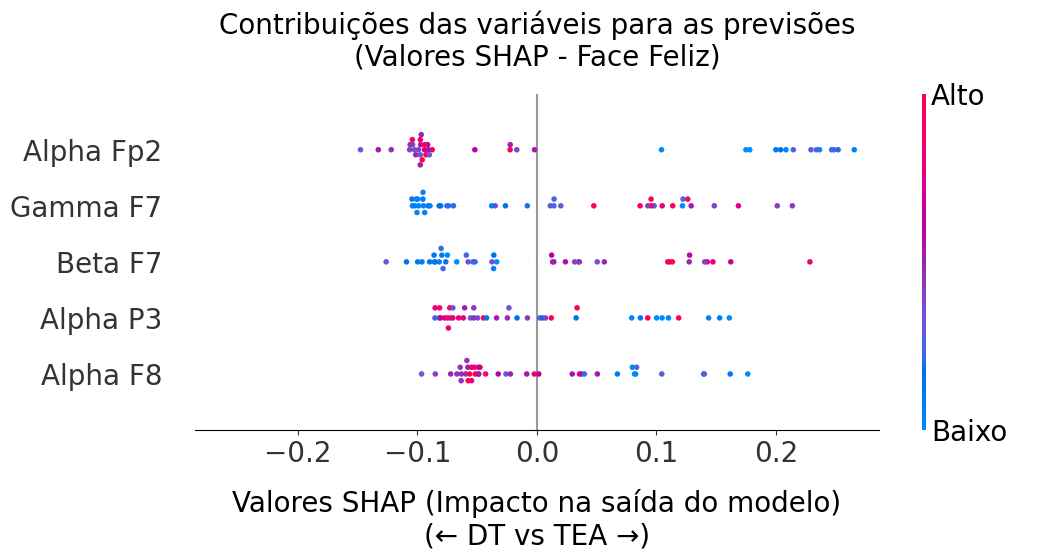

✅ SHAP Values com nomenclatura polida gerados e salvos em: ../reports/figures/fig04_shap_summary.png


In [13]:
# 09. VISUALIZAÇÃO: EXPLAINABILITY (SHAP SUMMARY PLOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import os
import warnings

try:
    import shap
except ImportError:
    print("⚠️ A biblioteca 'shap' não está instalada. Execute '!pip install shap' e rode novamente.")
    shap = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais (Forçando 'normal' em tudo)
plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal', 
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Filtragem (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# 5 Variáveis Selecionadas 
features_ouro = ['AlphaRel_P3', 'AlphaRel_Fp2', 'BetaRel_F7', 'AlphaRel_F8', 'GammaRel_F7']
X_sel = df_f[features_ouro]

# LIMPEZA DE NOMES: Trocando 'AlphaRel_P3' por 'Alpha P3' (Como o humano lê)
nomes_limpos = [nome.replace('Rel_', ' ') for nome in features_ouro]

# 3. Treinamento Base
rf_modelo = RandomForestClassifier(random_state=42)
rf_modelo.fit(X_sel, y)

# 4. SHAP Values
if shap is not None:
    # Proporção equilibrada para 5 variáveis
    fig = plt.figure(figsize=(11, 6))
    
    explainer = shap.TreeExplainer(rf_modelo)
    shap_values = explainer.shap_values(X_sel)
    
    # Tratamento de compatibilidade de versão do SHAP
    if isinstance(shap_values, list):
        shap_values_tea = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
        shap_values_tea = shap_values[:, :, 1]
    else:
        shap_values_tea = shap_values

    # Injetando a lista de 'nomes_limpos' no argumento feature_names
    shap.summary_plot(shap_values_tea, X_sel, feature_names=nomes_limpos, show=False, plot_size=(11, 6))
    
    # Customização do Título e Eixos
    plt.title('Contribuições das variáveis para as previsões\n(Valores SHAP - Face Feliz)', pad=20, fontsize=20, fontweight='normal')
    
    ax = plt.gca()
    
    # Centralização do eixo x (0 no meio do gráfico)
    limites_x = ax.get_xlim()
    max_abs = max(abs(limites_x[0]), abs(limites_x[1]))
    ax.set_xlim(-max_abs, max_abs) 
    
    ax.set_xlabel('Valores SHAP (Impacto na saída do modelo)\n(← DT vs TEA →)', fontsize=20, fontweight='normal', labelpad=15)
    ax.tick_params(axis='both', labelsize=20)
    
    # Ajuste da Barra de Cores (Feature Value)
    fig = plt.gcf()
    for eixo in fig.axes:
        if eixo != ax: 
            eixo.set_ylabel(' ', fontsize=20, fontweight='normal') 
            eixo.set_yticks([0, 1])
            eixo.set_yticklabels(['Baixo', 'Alto'], fontsize=20, fontweight='normal')
            eixo.tick_params(length=0) 
    
    plt.tight_layout()
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_fig = '../reports/figures/fig04_shap_summary.png'
    plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ SHAP Values com nomenclatura polida gerados e salvos em: {caminho_fig}")

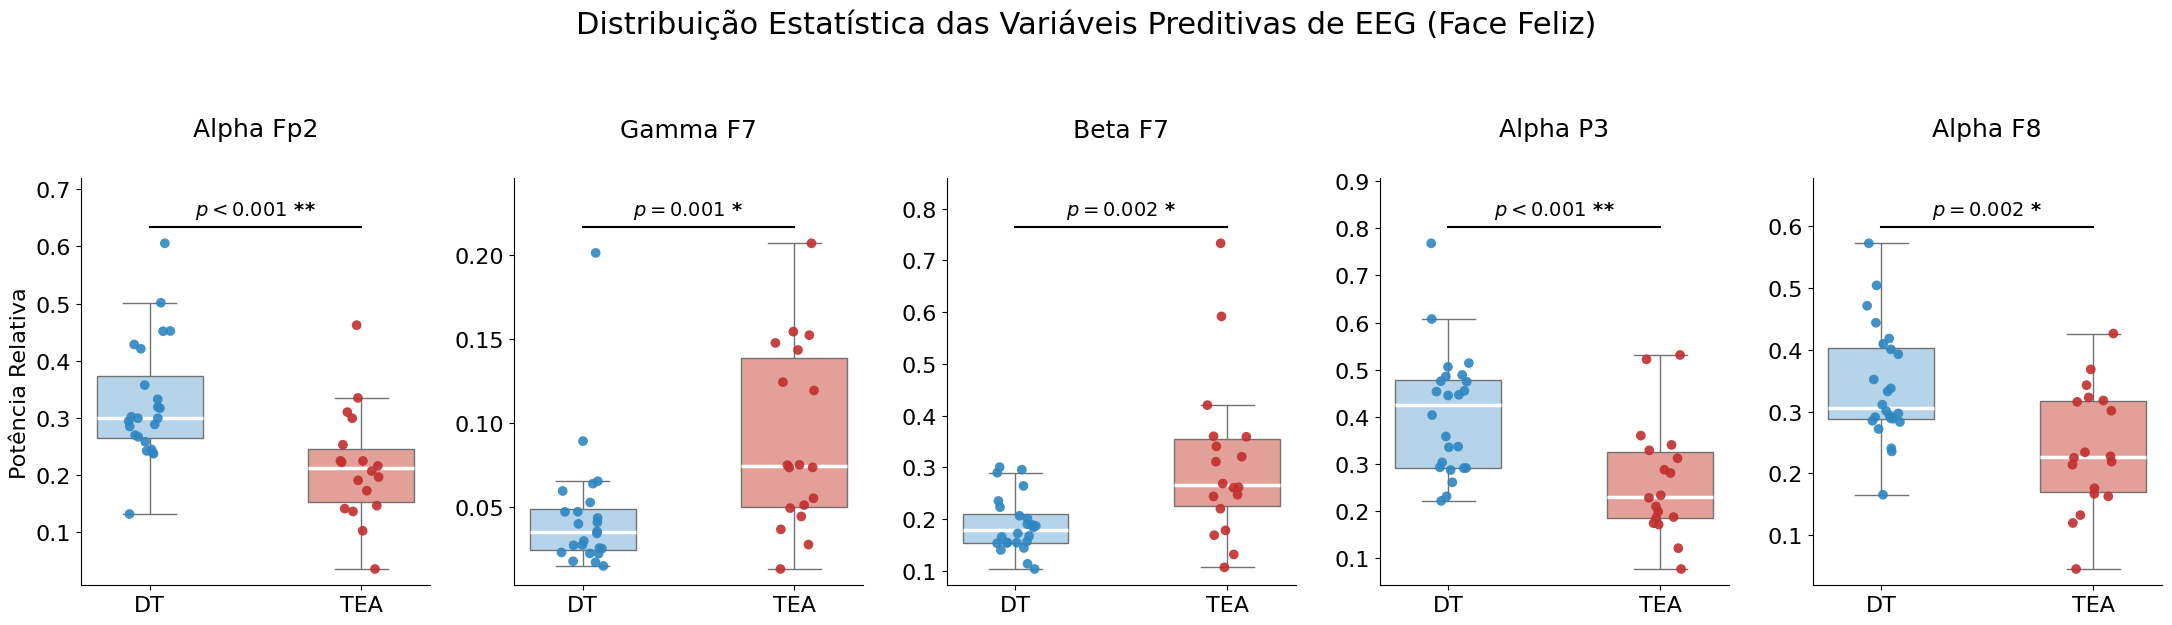

Boxplots gerados e salvos com sucesso!
Arquivo: ../reports/figures/figS1_distribuicao_variaveis.png


In [22]:

# 11. EXPLORAÇÃO SUPLEMENTAR (S1): DISTRIBUIÇÃO ESTATÍSTICA DAS VARIÁVEIS PREDITIVAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

df_f['Grupo_Plot'] = df_f['Grupo'].apply(
    lambda x: 'TEA' if 'TEA' in x else 'Controle'
)

features_ouro = [
    'AlphaRel_Fp2',
    'GammaRel_F7',
    'BetaRel_F7',
    'AlphaRel_P3',
    'AlphaRel_F8'
]

nomes_limpos = [
    'Alpha Fp2',
    'Gamma F7',
    'Beta F7',
    'Alpha P3',
    'Alpha F8'
]

# 3. Definição de Cores
# Azul (Controle) e Vermelho (TEA)
paleta_boxes = {
    'Controle': '#AED6F1',
    'TEA': '#F0968B'
}

# Cores mais escuras para os pontos individuais
paleta_dots = {
    'Controle': '#2E86C1',
    'TEA': '#C12E2E'
}

# 4. Preparação do Gráfico
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

fig.suptitle(
    'Distribuição Estatística das Variáveis Preditivas de EEG (Face Feliz)',
    fontsize=22,
    y=1.05
)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):

    g_ctrl = df_f[df_f['Grupo_Plot'] == 'Controle'][feature].dropna()
    g_asd = df_f[df_f['Grupo_Plot'] == 'TEA'][feature].dropna()

    # Teste de Normalidade e Seleção do Teste Estatístico
    _, p_shapiro_ctrl = stats.shapiro(g_ctrl)
    _, p_shapiro_asd = stats.shapiro(g_asd)

    if p_shapiro_ctrl > 0.05 and p_shapiro_asd > 0.05:
        stat, p_val = stats.ttest_ind(
            g_ctrl, g_asd, equal_var=False
        )
    else:
        stat, p_val = stats.mannwhitneyu(
            g_ctrl, g_asd, alternative='two-sided'
        )

    # Boxplots
    sns.boxplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        order=['Controle', 'TEA'],
        palette=paleta_boxes,
        ax=ax,
        width=0.5,
        showfliers=False,
        boxprops=dict(alpha=1.0),
        medianprops=dict(color='white', linewidth=2.5)
    )

    # Pontos individuais
    sns.stripplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        hue='Grupo_Plot',
        order=['Controle', 'TEA'],
        palette=paleta_dots,
        size=7,
        alpha=0.9,
        jitter=True,
        ax=ax,
        legend=False
    )

    # Ajustes estéticos
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')

    if ax == axes[0]:
        ax.set_ylabel('Potência Relativa')
    else:
        ax.set_ylabel('')

    # Rótulos do eixo X
    ax.set_xticklabels(['DT', 'TEA'])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Anotação do valor de p
    y_max = df_f[feature].max()
    y_range = y_max - df_f[feature].min()

    if y_range == 0:
        y_range = abs(y_max) if y_max != 0 else 1

    y_text = y_max + (y_range * 0.05)

    if p_val < 0.001:
        p_text = "$p < 0.001$ **"
        font_weight = 'bold'

    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ *"
        font_weight = 'bold'

    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'

    ax.plot(
        [0, 1],
        [y_text, y_text],
        color='black',
        lw=1.5
    )

    ax.text(
        0.5,
        y_text + (y_range * 0.02),
        p_text,
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight=font_weight
    )

    ax.set_ylim(
        df_f[feature].min() - (y_range * 0.05),
        y_text + (y_range * 0.15)
    )

plt.tight_layout()

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)

caminho_fig = '../reports/figures/figS1_distribuicao_variaveis.png'

plt.savefig(
    caminho_fig,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("Boxplots gerados e salvos com sucesso!")
print(f"Arquivo: {caminho_fig}")


📊 RESULTADOS DA AUDITORIA ESTATÍSTICA:
--------------------------------------------------
[Alpha Fp2] Teste: Mann-Whitney | p-value: 0.0006
[Gamma F7] Teste: Mann-Whitney | p-value: 0.0012
[Beta F7] Teste: Mann-Whitney | p-value: 0.0022
[Alpha P3] Teste: T-test | p-value: 0.0008
[Alpha F8] Teste: T-test | p-value: 0.0019


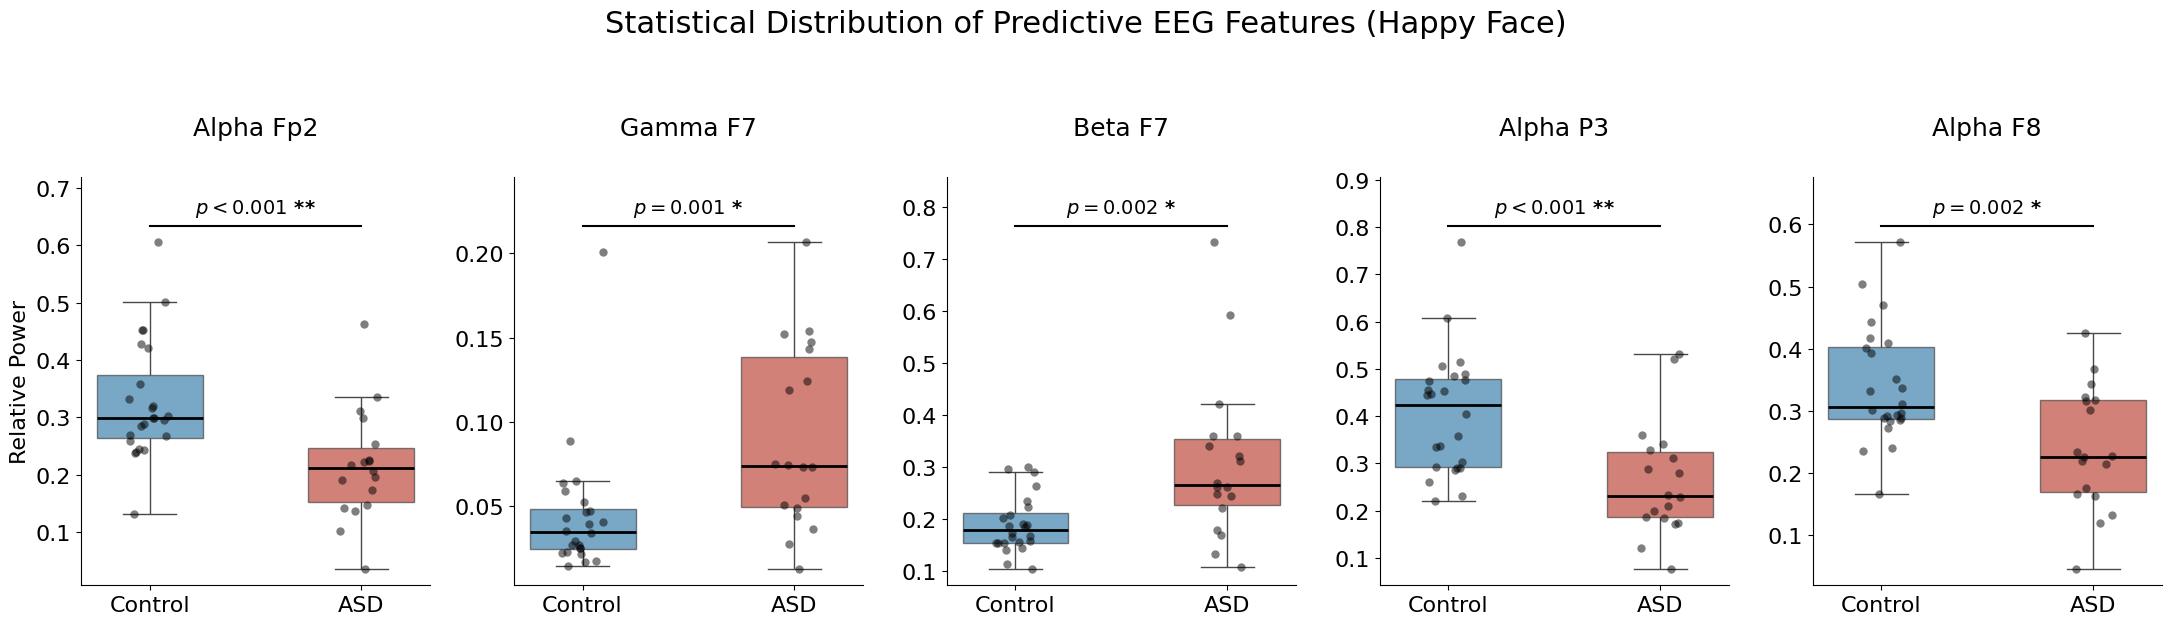

--------------------------------------------------
✅ Boxplots Estatísticos gerados e salvos em: ../reports/figures/figS1_features_distribution.png


In [17]:
# 10. EXPLORAÇÃO SUPLEMENTAR (S1): STATISTICAL DISTRIBUTION OF GOLDEN FEATURES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais (Estilo acadêmico e limpo)
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# Padronizando a nomenclatura dos grupos para o Plot
df_f['Grupo_Plot'] = df_f['Grupo'].apply(lambda x: 'ASD' if 'TEA' in x else 'Control')

# As 5 Features de Ouro do seu modelo
features_ouro = ['AlphaRel_Fp2', 'GammaRel_F7', 'BetaRel_F7', 'AlphaRel_P3', 'AlphaRel_F8']
nomes_limpos = ['Alpha Fp2', 'Gamma F7', 'Beta F7', 'Alpha P3', 'Alpha F8']

# 3. Preparação do Plot (1 Linha, 5 Colunas)
fig, axes = plt.subplots(1, 5, figsize=(22, 6))
fig.suptitle('Statistical Distribution of Predictive EEG Features (Happy Face)', fontsize=22, y=1.05)

# Paleta inspirada nos artigos clássicos: Controle (Azul), TEA (Vermelho/Rosa)
paleta = {'Control': '#2E86C1', 'ASD': "#D43B2A"}

print("📊 RESULTADOS DA AUDITORIA ESTATÍSTICA:\n" + "-"*50)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):
    # Isolando os grupos e removendo NaNs por segurança
    g_ctrl = df_f[df_f['Grupo_Plot'] == 'Control'][feature].dropna()
    g_asd = df_f[df_f['Grupo_Plot'] == 'ASD'][feature].dropna()
    
    # --- TESTE DE NORMALIDADE (Shapiro-Wilk) ---
    _, p_shapiro_ctrl = stats.shapiro(g_ctrl)
    _, p_shapiro_asd = stats.shapiro(g_asd)
    
    # --- ÁRVORE DE DECISÃO ESTATÍSTICA ---
    if p_shapiro_ctrl > 0.05 and p_shapiro_asd > 0.05:
        # Ambos normais -> Teste T (assumindo variâncias desiguais por segurança: Welch's t-test)
        stat, p_val = stats.ttest_ind(g_ctrl, g_asd, equal_var=False)
        nome_teste = "T-test"
    else:
        # Pelo menos um não-normal -> Mann-Whitney U
        stat, p_val = stats.mannwhitneyu(g_ctrl, g_asd, alternative='two-sided')
        nome_teste = "Mann-Whitney"
        
    print(f"[{nome_limpo}] Teste: {nome_teste} | p-value: {p_val:.4f}")

    # --- PLOTAGEM DO BOXPLOT + PONTOS INDIVIDUAIS ---
    sns.boxplot(data=df_f, x='Grupo_Plot', y=feature, order=['Control', 'ASD'],
                palette=paleta, ax=ax, width=0.5, showfliers=False, 
                boxprops=dict(alpha=0.7), medianprops=dict(color='black', linewidth=2))
    
    sns.stripplot(data=df_f, x='Grupo_Plot', y=feature, order=['Control', 'ASD'],
                  color='black', size=6, alpha=0.5, jitter=True, ax=ax)
    
    # Ajustes estéticos de cada eixo
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')
    if ax == axes[0]:
        ax.set_ylabel('Relative Power')
    else:
        ax.set_ylabel('')
        
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # --- ANOTAÇÃO DO VALOR P NO GRÁFICO ---
    # Encontrar a altura máxima do plot para colocar o texto do p-value
    y_max = df_f[feature].max()
    y_range = y_max - df_f[feature].min()
    y_text = y_max + (y_range * 0.05)
    
    # Formatação do texto: se p < 0.05 adiciona asterisco, senao deixa só o valor
    if p_val < 0.001:
        p_text = "$p < 0.001$ **"
        font_weight = 'bold'
    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ *"
        font_weight = 'bold'
    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'
        
    # Desenhando a linha e o texto
    ax.plot([0, 1], [y_text, y_text], color='black', lw=1.5)
    ax.text(0.5, y_text + (y_range * 0.02), p_text, ha='center', va='bottom', 
            fontsize=14, fontweight=font_weight)
    
    # Ajustar o limite do y para o texto não cortar
    ax.set_ylim(df_f[feature].min() - (y_range*0.05), y_text + (y_range * 0.15))

plt.tight_layout()

# 4. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_fig = '../reports/figures/figS1_features_distribution.png'
plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
plt.show()

print("-" * 50)
print(f"✅ Boxplots Estatísticos gerados e salvos em: {caminho_fig}")

In [ ]:

# 11. EXPLORAÇÃO SUPLEMENTAR (S1): DISTRIBUIÇÃO ESTATÍSTICA DAS VARIÁVEIS PREDITIVAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações visuais
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e preparação dos dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

df_f['Grupo_Plot'] = df_f['Grupo'].apply(
    lambda x: 'TEA' if 'TEA' in x else 'DT'
)

# Cinco variáveis preditivas selecionadas
features_ouro = [
    'AlphaRel_Fp2',
    'GammaRel_F7',
    'BetaRel_F7',
    'AlphaRel_P3',
    'AlphaRel_F8'
]

# Nomes em português para exibição
nomes_limpos = [
    'Alfa Fp2',
    'Gama F7',
    'Beta F7',
    'Alfa P3',
    'Alfa F8'
]

# 3. Definição das cores
# Azul para DT e vermelho para TEA
paleta_boxes = {
    'DT': '#AED6F1',
    'TEA': '#F0968B'
}

# Cores mais escuras para os pontos individuais
paleta_dots = {
    'DT': '#2E86C1',
    'TEA': '#C12E2E'
}

# 4. Preparação do gráfico
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

fig.suptitle(
    'Distribuição estatística das variáveis preditivas de EEG (Face Feliz)',
    fontsize=22,
    y=1.05
)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):

    g_dt = df_f[df_f['Grupo_Plot'] == 'DT'][feature].dropna()
    g_tea = df_f[df_f['Grupo_Plot'] == 'TEA'][feature].dropna()

    # Teste de normalidade e seleção do teste estatístico
    _, p_shapiro_dt = stats.shapiro(g_dt)
    _, p_shapiro_tea = stats.shapiro(g_tea)

    if p_shapiro_dt > 0.05 and p_shapiro_tea > 0.05:
        stat, p_val = stats.ttest_ind(
            g_dt, g_tea, equal_var=False
        )
    else:
        stat, p_val = stats.mannwhitneyu(
            g_dt, g_tea, alternative='two-sided'
        )

    # Gráfico de caixas
    sns.boxplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        order=['DT', 'TEA'],
        palette=paleta_boxes,
        ax=ax,
        width=0.5,
        showfliers=False,
        boxprops=dict(alpha=1.0),
        medianprops=dict(color='white', linewidth=2.5)
    )

    # Pontos individuais
    sns.stripplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        hue='Grupo_Plot',
        order=['DT', 'TEA'],
        palette=paleta_dots,
        size=7,
        alpha=0.9,
        jitter=True,
        ax=ax,
        legend=False
    )

    # Ajustes estéticos
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')

    if ax == axes[0]:
        ax.set_ylabel('Potência relativa')
    else:
        ax.set_ylabel('')

    # Identificação dos grupos
    ax.set_xticklabels(['DT', 'TEA'])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Anotação do valor de p
    y_max = df_f[feature].max()
    y_min = df_f[feature].min()
    y_range = y_max - y_min

    if y_range == 0:
        y_range = abs(y_max) if y_max != 0 else 1

    y_text = y_max + (y_range * 0.05)

    if p_val < 0.001:
        p_text = "$p < 0.001$ **"
        font_weight = 'bold'

    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ *"
        font_weight = 'bold'

    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'

    ax.plot(
        [0, 1],
        [y_text, y_text],
        color='black',
        lw=1.5
    )

    ax.text(
        0.5,
        y_text + (y_range * 0.02),
        p_text,
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight=font_weight
    )

    ax.set_ylim(
        y_min - (y_range * 0.05),
        y_text + (y_range * 0.15)
    )

# 5. Ajustes finais
plt.tight_layout()

# 6. Salvamento da imagem
os.makedirs('../reports/figures', exist_ok=True)

caminho_fig = '../reports/figures/figS1_distribuicao_variaveis.png'

plt.savefig(
    caminho_fig,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("Gráficos de distribuição estatística gerados com sucesso!")
print(f"Imagem salva em: {caminho_fig}")


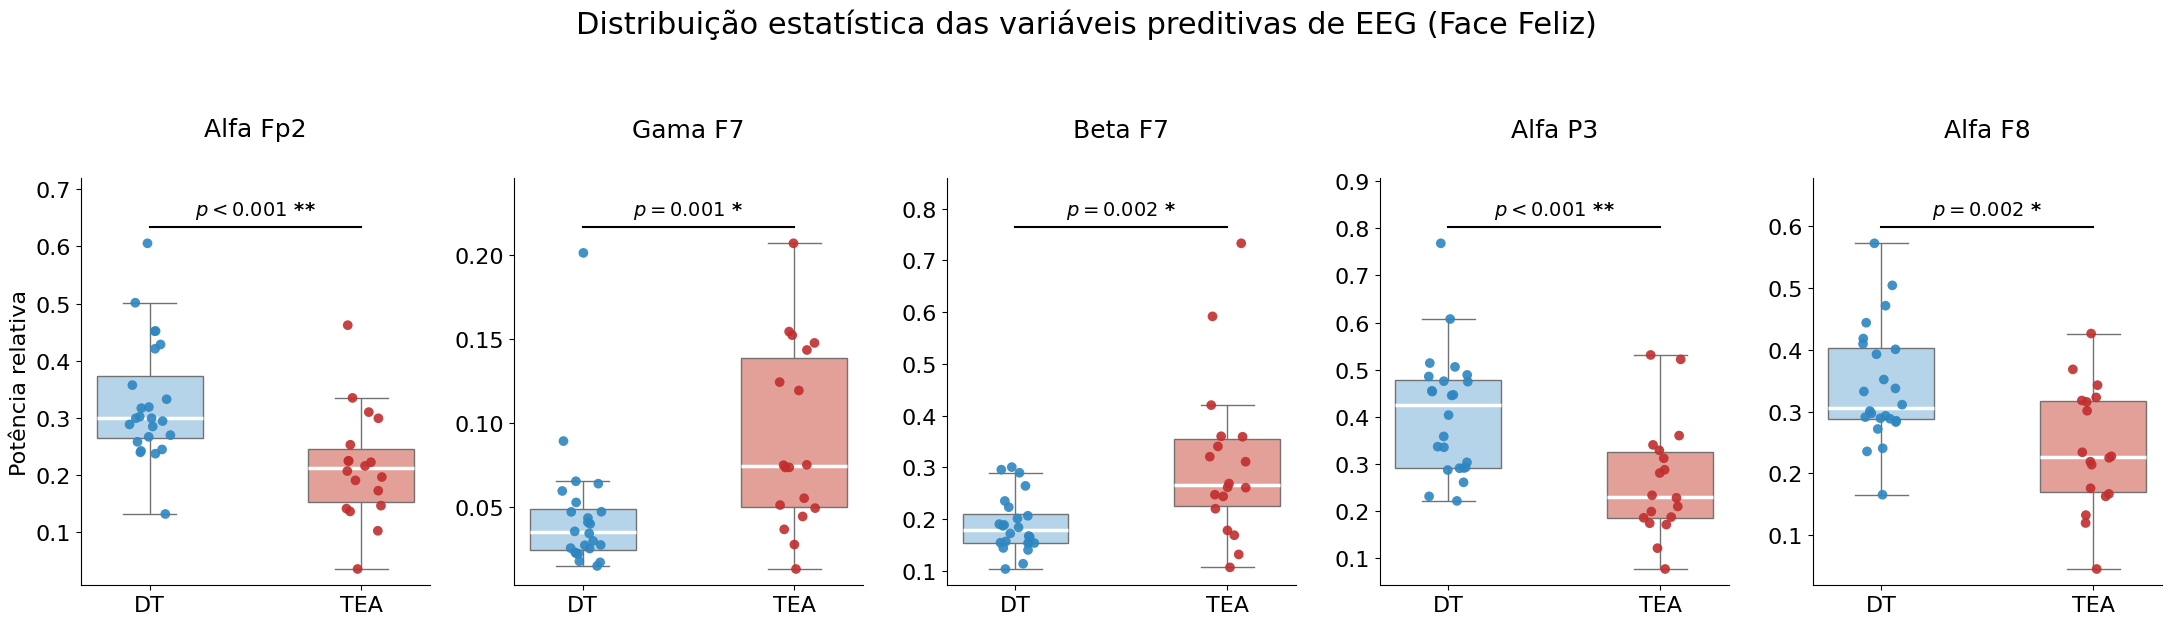

Gráficos de distribuição estatística gerados com sucesso!
Imagem salva em: ../reports/figures/figS1_distribuicao_variaveis.png


In [ ]:
# 11. EXPLORAÇÃO SUPLEMENTAR (S1): DISTRIBUIÇÃO ESTATÍSTICA DAS VARIÁVEIS PREDITIVAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações visuais
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e preparação dos dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

df_f['Grupo_Plot'] = df_f['Grupo'].apply(
    lambda x: 'TEA' if 'TEA' in x else 'DT'
)

# Cinco variáveis preditivas selecionadas
features_ouro = [
    'AlphaRel_Fp2',
    'GammaRel_F7',
    'BetaRel_F7',
    'AlphaRel_P3',
    'AlphaRel_F8'
]

# Nomes em português para exibição
nomes_limpos = [
    'Alfa Fp2',
    'Gama F7',
    'Beta F7',
    'Alfa P3',
    'Alfa F8'
]

# 3. Definição das cores
# Azul para DT e vermelho para TEA
paleta_boxes = {
    'DT': '#AED6F1',
    'TEA': '#F0968B'
}

# Cores mais escuras para os pontos individuais
paleta_dots = {
    'DT': '#2E86C1',
    'TEA': '#C12E2E'
}

# 4. Preparação do gráfico
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

fig.suptitle(
    'Distribuição estatística das variáveis preditivas de EEG (Face Feliz)',
    fontsize=22,
    y=1.05
)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):

    g_dt = df_f[df_f['Grupo_Plot'] == 'DT'][feature].dropna()
    g_tea = df_f[df_f['Grupo_Plot'] == 'TEA'][feature].dropna()

    # Teste de normalidade e seleção do teste estatístico
    _, p_shapiro_dt = stats.shapiro(g_dt)
    _, p_shapiro_tea = stats.shapiro(g_tea)

    if p_shapiro_dt > 0.05 and p_shapiro_tea > 0.05:
        stat, p_val = stats.ttest_ind(
            g_dt, g_tea, equal_var=False
        )
    else:
        stat, p_val = stats.mannwhitneyu(
            g_dt, g_tea, alternative='two-sided'
        )

    # Gráfico de caixas
    sns.boxplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        order=['DT', 'TEA'],
        palette=paleta_boxes,
        ax=ax,
        width=0.5,
        showfliers=False,
        boxprops=dict(alpha=1.0),
        medianprops=dict(color='white', linewidth=2.5)
    )

    # Pontos individuais
    sns.stripplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        hue='Grupo_Plot',
        order=['DT', 'TEA'],
        palette=paleta_dots,
        size=7,
        alpha=0.9,
        jitter=True,
        ax=ax,
        legend=False
    )

    # Ajustes estéticos
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')

    if ax == axes[0]:
        ax.set_ylabel('Potência Relativa')
    else:
        ax.set_ylabel('')

    # Identificação dos grupos
    ax.set_xticklabels(['DT', 'TEA'])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Anotação do valor de p
    y_max = df_f[feature].max()
    y_min = df_f[feature].min()
    y_range = y_max - y_min

    if y_range == 0:
        y_range = abs(y_max) if y_max != 0 else 1

    y_text = y_max + (y_range * 0.05)

    if p_val < 0.001:
        p_text = "$p < 0.001$ **"
        font_weight = 'bold'

    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ *"
        font_weight = 'bold'

    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'

    ax.plot(
        [0, 1],
        [y_text, y_text],
        color='black',
        lw=1.5
    )

    ax.text(
        0.5,
        y_text + (y_range * 0.02),
        p_text,
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight=font_weight
    )

    ax.set_ylim(
        y_min - (y_range * 0.05),
        y_text + (y_range * 0.15)
    )

# 5. Ajustes finais
plt.tight_layout()

# 6. Salvamento da imagem
os.makedirs('../reports/figures', exist_ok=True)

caminho_fig = '../reports/figures/figS1_distribuicao_variaveis.png'

plt.savefig(
    caminho_fig,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("Gráficos de distribuição estatística gerados com sucesso!")
print(f"Imagem salva em: {caminho_fig}")


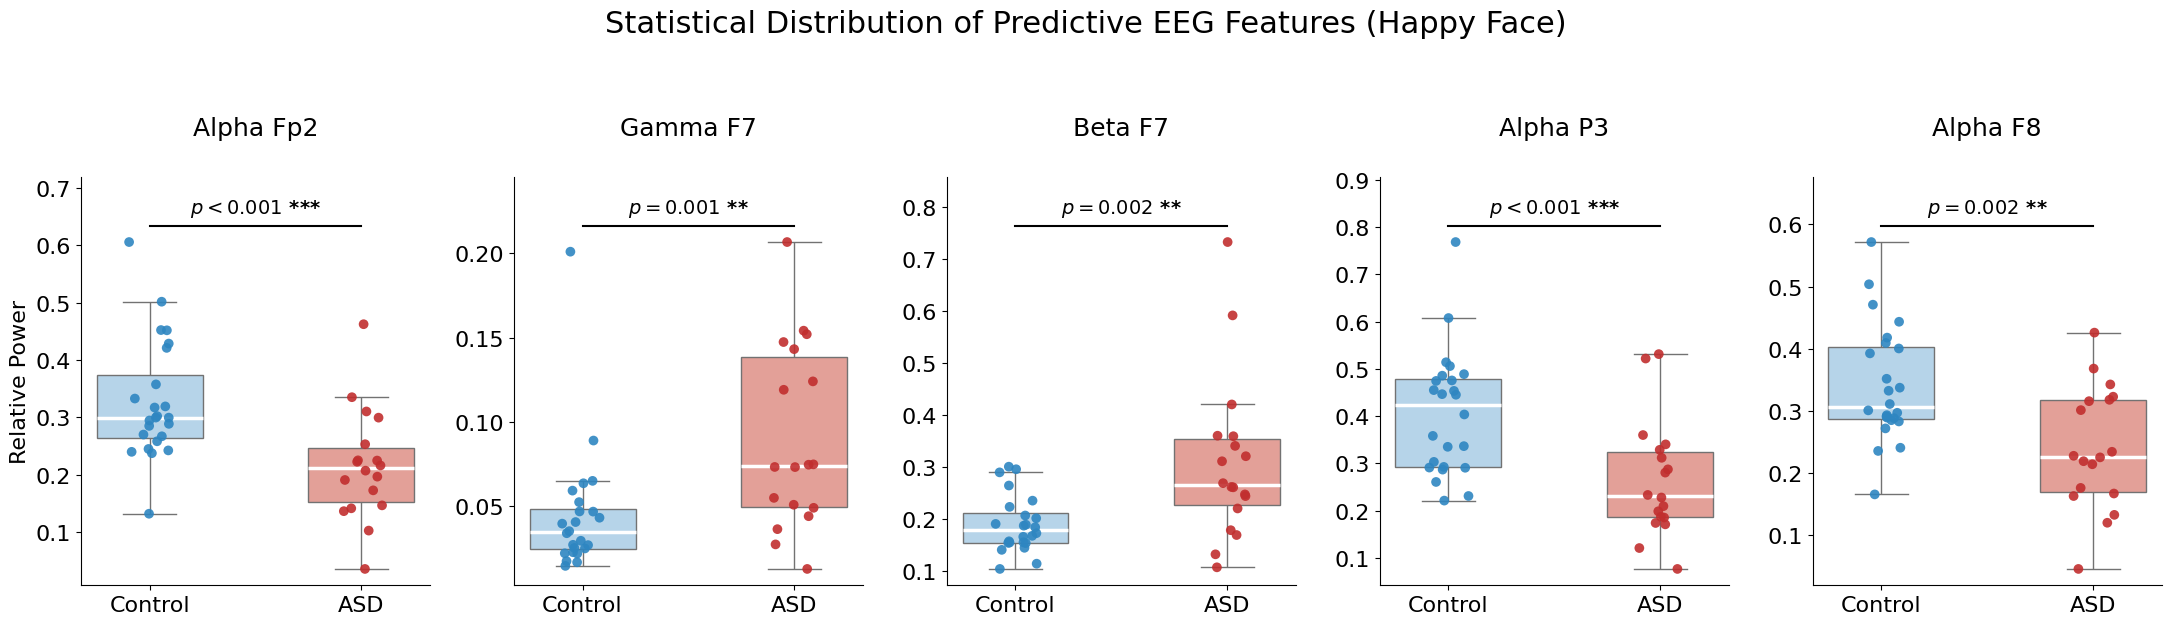

✅ Boxplots esteticamente ajustados gerados com sucesso!


In [3]:
# 11. EXPLORAÇÃO SUPLEMENTAR (S1): STATISTICAL DISTRIBUTION OF GOLDEN FEATURES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

df_f['Grupo_Plot'] = df_f['Grupo'].apply(lambda x: 'ASD' if 'TEA' in x else 'Control')

features_ouro = ['AlphaRel_Fp2', 'GammaRel_F7', 'BetaRel_F7', 'AlphaRel_P3', 'AlphaRel_F8']
nomes_limpos = ['Alpha Fp2', 'Gamma F7', 'Beta F7', 'Alpha P3', 'Alpha F8']

# 3. Definição Exata de Cores (Sólidas e Vibrantes)
# Azul Forte (Controle) e Vermelho Vivo (TEA)
paleta_boxes = {'Control': '#AED6F1', 'ASD': "#F0968B"}
# Azul Escuro e Vermelho Escuro/Vinho para as bolinhas se destacarem do fundo
paleta_dots = {'Control': '#2E86C1', 'ASD': "#C12E2E"}

# 4. Preparação do Plot
fig, axes = plt.subplots(1, 5, figsize=(22, 6))
fig.suptitle('Statistical Distribution of Predictive EEG Features (Happy Face)', fontsize=22, y=1.05)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):
    g_ctrl = df_f[df_f['Grupo_Plot'] == 'Control'][feature].dropna()
    g_asd = df_f[df_f['Grupo_Plot'] == 'ASD'][feature].dropna()
    
    # Teste de Normalidade e Árvore de Decisão
    _, p_shapiro_ctrl = stats.shapiro(g_ctrl)
    _, p_shapiro_asd = stats.shapiro(g_asd)
    
    if p_shapiro_ctrl > 0.05 and p_shapiro_asd > 0.05:
        stat, p_val = stats.ttest_ind(g_ctrl, g_asd, equal_var=False)
    else:
        stat, p_val = stats.mannwhitneyu(g_ctrl, g_asd, alternative='two-sided')

    # PLOTAGEM DAS CAIXAS (alpha=1.0 remove a transparência pastel)
    # Linha da mediana definida como branca ('white') para dar contraste
    sns.boxplot(data=df_f, x='Grupo_Plot', y=feature, order=['Control', 'ASD'],
                palette=paleta_boxes, ax=ax, width=0.5, showfliers=False, 
                boxprops=dict(alpha=1.0), medianprops=dict(color='white', linewidth=2.5))
    
    # PLOTAGEM DOS PONTOS (Utilizando hue e palette separada para as bordas não sumirem)
    sns.stripplot(data=df_f, x='Grupo_Plot', y=feature, hue='Grupo_Plot', order=['Control', 'ASD'],
                  palette=paleta_dots, size=7, alpha=0.9, jitter=True, ax=ax, legend=False)
    
    # Ajustes estéticos
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')
    if ax == axes[0]:
        ax.set_ylabel('Relative Power')
    else:
        ax.set_ylabel('')
        
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # ANOTAÇÃO DO VALOR P
    y_max = df_f[feature].max()
    y_range = y_max - df_f[feature].min()
    y_text = y_max + (y_range * 0.05)
    
    if p_val < 0.001:
        p_text = "$p < 0.001$ ***"
        font_weight = 'bold'
    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ **"
        font_weight = 'bold'
    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'
        
    ax.plot([0, 1], [y_text, y_text], color='black', lw=1.5)
    ax.text(0.5, y_text + (y_range * 0.02), p_text, ha='center', va='bottom', 
            fontsize=14, fontweight=font_weight)
    
    ax.set_ylim(df_f[feature].min() - (y_range*0.05), y_text + (y_range * 0.15))

plt.tight_layout()

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_fig = '../reports/figures/figS1_features_distribution.png'
plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
plt.show()

print("✅ Boxplots esteticamente ajustados gerados com sucesso!")

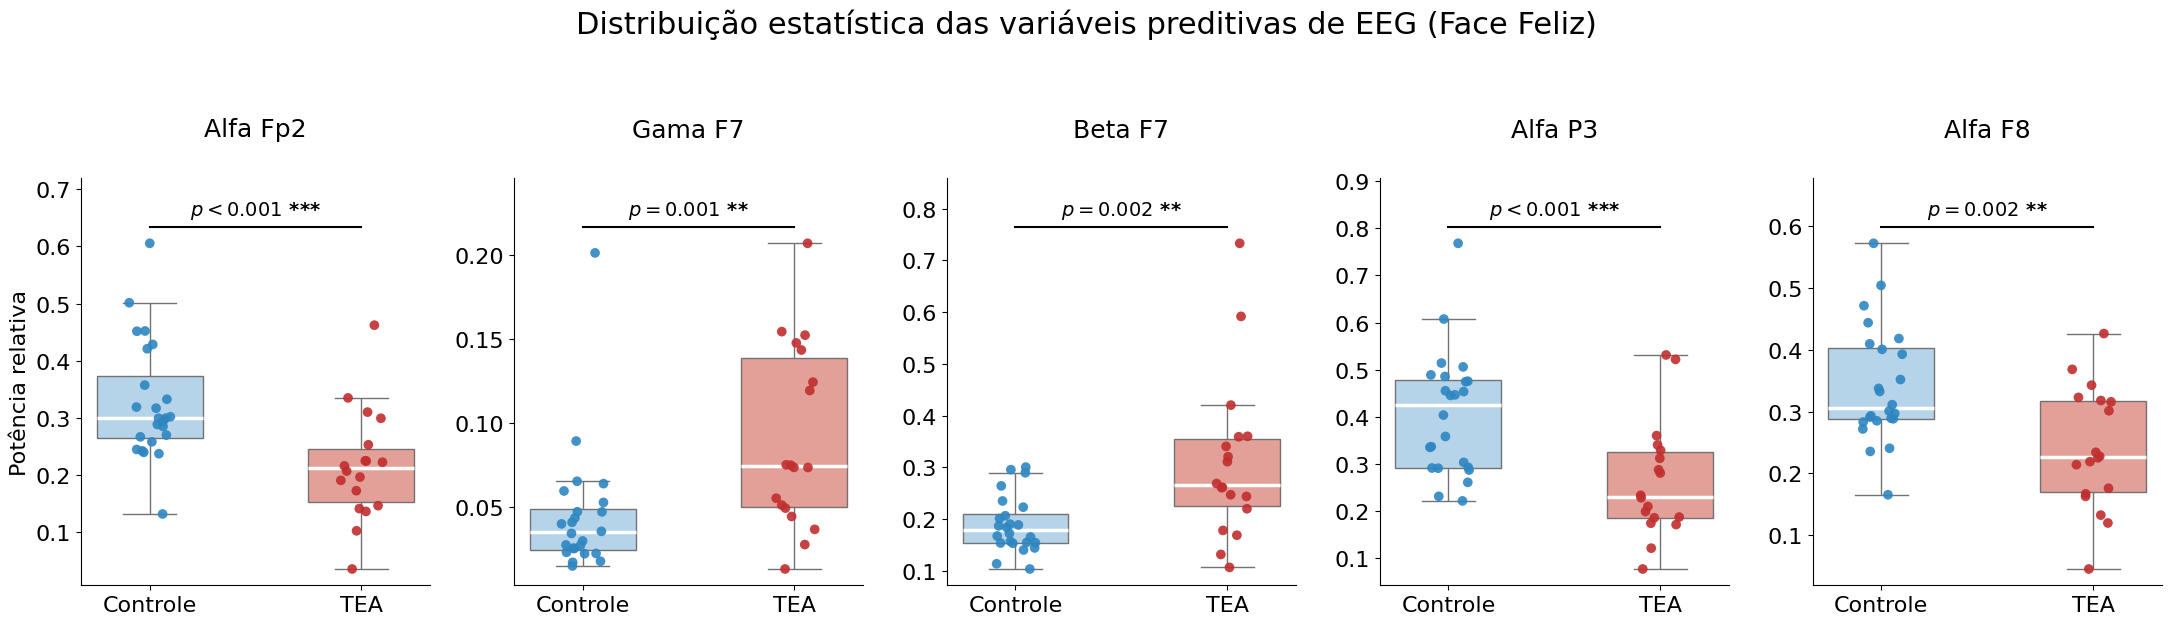

Boxplots gerados e salvos com sucesso!
Arquivo: ../reports/figures/figS1_distribuicao_variaveis.png


In [2]:

# 11. EXPLORAÇÃO SUPLEMENTAR (S1): DISTRIBUIÇÃO ESTATÍSTICA DAS VARIÁVEIS PREDITIVAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'font.weight': 'normal',
    'axes.labelweight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

df_f['Grupo_Plot'] = df_f['Grupo'].apply(
    lambda x: 'TEA' if 'TEA' in x else 'Controle'
)

features_ouro = [
    'AlphaRel_Fp2',
    'GammaRel_F7',
    'BetaRel_F7',
    'AlphaRel_P3',
    'AlphaRel_F8'
]

nomes_limpos = [
    'Alfa Fp2',
    'Gama F7',
    'Beta F7',
    'Alfa P3',
    'Alfa F8'
]

# 3. Definição de Cores
# Azul (Controle) e Vermelho (TEA)
paleta_boxes = {
    'Controle': '#AED6F1',
    'TEA': '#F0968B'
}

# Cores mais escuras para os pontos individuais
paleta_dots = {
    'Controle': '#2E86C1',
    'TEA': '#C12E2E'
}

# 4. Preparação do Gráfico
fig, axes = plt.subplots(1, 5, figsize=(22, 6))

fig.suptitle(
    'Distribuição estatística das variáveis preditivas de EEG (Face Feliz)',
    fontsize=22,
    y=1.05
)

for ax, feature, nome_limpo in zip(axes, features_ouro, nomes_limpos):

    g_ctrl = df_f[df_f['Grupo_Plot'] == 'Controle'][feature].dropna()
    g_asd = df_f[df_f['Grupo_Plot'] == 'TEA'][feature].dropna()

    # Teste de Normalidade e Seleção do Teste Estatístico
    _, p_shapiro_ctrl = stats.shapiro(g_ctrl)
    _, p_shapiro_asd = stats.shapiro(g_asd)

    if p_shapiro_ctrl > 0.05 and p_shapiro_asd > 0.05:
        stat, p_val = stats.ttest_ind(
            g_ctrl, g_asd, equal_var=False
        )
    else:
        stat, p_val = stats.mannwhitneyu(
            g_ctrl, g_asd, alternative='two-sided'
        )

    # Boxplots
    sns.boxplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        order=['Controle', 'TEA'],
        palette=paleta_boxes,
        ax=ax,
        width=0.5,
        showfliers=False,
        boxprops=dict(alpha=1.0),
        medianprops=dict(color='white', linewidth=2.5)
    )

    # Pontos individuais
    sns.stripplot(
        data=df_f,
        x='Grupo_Plot',
        y=feature,
        hue='Grupo_Plot',
        order=['Controle', 'TEA'],
        palette=paleta_dots,
        size=7,
        alpha=0.9,
        jitter=True,
        ax=ax,
        legend=False
    )

    # Ajustes estéticos
    ax.set_title(nome_limpo, pad=30)
    ax.set_xlabel('')

    if ax == axes[0]:
        ax.set_ylabel('Potência relativa')
    else:
        ax.set_ylabel('')

    # Rótulos do eixo X
    ax.set_xticklabels(['Controle', 'TEA'])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Anotação do valor de p
    y_max = df_f[feature].max()
    y_range = y_max - df_f[feature].min()

    if y_range == 0:
        y_range = abs(y_max) if y_max != 0 else 1

    y_text = y_max + (y_range * 0.05)

    if p_val < 0.001:
        p_text = "$p < 0.001$ ***"
        font_weight = 'bold'

    elif p_val < 0.05:
        p_text = f"$p = {p_val:.3f}$ **"
        font_weight = 'bold'

    else:
        p_text = f"$p = {p_val:.3f}$"
        font_weight = 'normal'

    ax.plot(
        [0, 1],
        [y_text, y_text],
        color='black',
        lw=1.5
    )

    ax.text(
        0.5,
        y_text + (y_range * 0.02),
        p_text,
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight=font_weight
    )

    ax.set_ylim(
        df_f[feature].min() - (y_range * 0.05),
        y_text + (y_range * 0.15)
    )

plt.tight_layout()

# 5. Salvamento
os.makedirs('../reports/figures', exist_ok=True)

caminho_fig = '../reports/figures/figS1_distribuicao_variaveis.png'

plt.savefig(
    caminho_fig,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("Boxplots gerados e salvos com sucesso!")
print(f"Arquivo: {caminho_fig}")


⚠️ Atenção: A imagem 'brain_background.png' não foi encontrada no diretório do script!
⚠️ Atenção: A imagem 'brain_background.png' não foi encontrada no diretório do script!


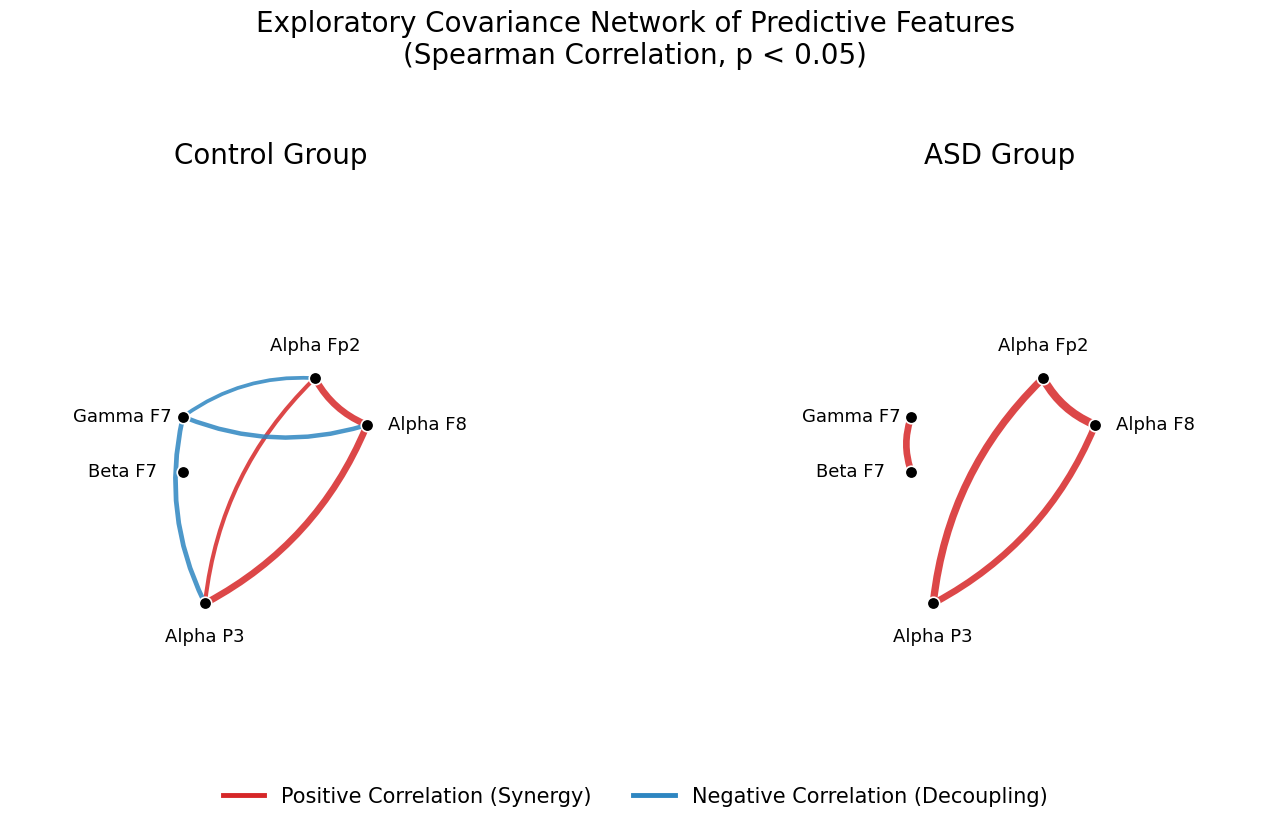

✅ Figura S2 gerada com os canais encaixados dentro do crânio!


In [16]:
# 12. EXPLORAÇÃO SUPLEMENTAR (S2): TOPOLOGICAL CORRELATION NETWORK (FINAL CALIBRATION)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais (Tipografia limpa, sem negritos)
plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'axes.labelweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values
df_tea = df_f[y == 1]
df_ctrl = df_f[y == 0]

# 3. Coordenadas dos Eletrodos Calibrated para o Interior do Crânio
features_ouro = ['AlphaRel_Fp2', 'GammaRel_F7', 'BetaRel_F7', 'AlphaRel_P3', 'AlphaRel_F8']
nomes_limpos = ['Alpha Fp2', 'Gamma F7', 'Beta F7', 'Alpha P3', 'Alpha F8']

# Posições ajustadas para caírem exatamente sobre o encéfalo/linha interna
posicoes = {
    'Alpha Fp2': (0.16, 0.42),
    'Gamma F7': (-0.32, 0.28),
    'Beta F7': (-0.32, 0.08),
    'Alpha F8': (0.35, 0.25),
    'Alpha P3': (-0.24, -0.40)
}

# 4. Motor de Plotagem da Rede sobre a Imagem de Fundo Proporcional
def plotar_rede(df_grupo, titulo, ax):
    ax.set_aspect('equal')
    
    # 4.1. Carrega e exibe a imagem base com extent exato (Aspect Ratio 0.8)
    caminho_bg = 'brain_background.png'
    if os.path.exists(caminho_bg):
        img_bg = plt.imread(caminho_bg)
        ax.imshow(img_bg, extent=[-0.800, 0.800, -1.000, 1.000], zorder=0)
    else:
        print(f"⚠️ Atenção: A imagem '{caminho_bg}' não foi encontrada no diretório do script!")

    ax.set_title(titulo, pad=10, fontsize=20, fontweight='normal')
    
    dados = df_grupo[features_ouro].dropna()
    n_features = len(features_ouro)
    
    # 4.2. Desenho das Arestas Curvas (Correlações de Spearman p < 0.05)
    for i in range(n_features):
        for j in range(i + 1, n_features):
            feat1, feat2 = features_ouro[i], features_ouro[j]
            nome1, nome2 = nomes_limpos[i], nomes_limpos[j]
            
            r, p = spearmanr(dados[feat1], dados[feat2])
            
            if p < 0.05:
                x1, y1 = posicoes[nome1]
                x2, y2 = posicoes[nome2]
                
                espessura = abs(r) * 6.5
                cor = '#D62728' if r > 0 else '#2E86C1'
                
                arco = FancyArrowPatch((x1, y1), (x2, y2),
                                       connectionstyle="arc3,rad=0.18",
                                       color=cor, lw=espessura, alpha=0.85, 
                                       zorder=3, arrowstyle="-")
                ax.add_patch(arco)

    # 4.3. Desenho dos Eletrodos (Nós) e Rótulos Estilizados
    for nome in nomes_limpos:
        x, y = posicoes[nome]
        
        # Ponto preto do eletrodo com contorno branco para destaque
        ax.plot(x, y, marker='o', markersize=9, color='black', 
                markeredgecolor='white', markeredgewidth=1.2, zorder=4)
        
        # Deslocamentos dos rótulos proporcionais
        if 'F7' in nome:
            desloc_x, desloc_y = -0.22, 0 
        elif 'F8' in nome:
            desloc_x, desloc_y = 0.22, 0
        elif 'Fp2' in nome:
            desloc_x, desloc_y = 0, 0.12
        else:
            desloc_x, desloc_y = 0, -0.12
            
        ax.text(x + desloc_x, y + desloc_y, nome, ha='center', va='center', 
                fontsize=13, fontweight='normal', color='black', zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))

    ax.set_xlim(-0.95, 0.95)
    ax.set_ylim(-1.15, 1.15)
    ax.axis('off')

# 5. Geração da Figura Final
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
fig.suptitle('Exploratory Covariance Network of Predictive Features\n(Spearman Correlation, p < 0.05)', 
             fontsize=20, y=1.03, fontweight='normal')

plotar_rede(df_ctrl, 'Control Group', axes[0])
plotar_rede(df_tea, 'ASD Group', axes[1])

# 6. Legenda Sem Moldura
legend_elements = [
    Line2D([0], [0], color='#D62728', lw=3.5, label='Positive Correlation (Synergy)'),
    Line2D([0], [0], color='#2E86C1', lw=3.5, label='Negative Correlation (Decoupling)')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, 
           bbox_to_anchor=(0.5, 0.01), fontsize=15, frameon=False)

plt.tight_layout()

# 7. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_fig = '../reports/figures/figS2_topology_network_anatomical.png'
plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
plt.show()

print("✅ Figura S2 gerada com os canais encaixados dentro do crânio!")

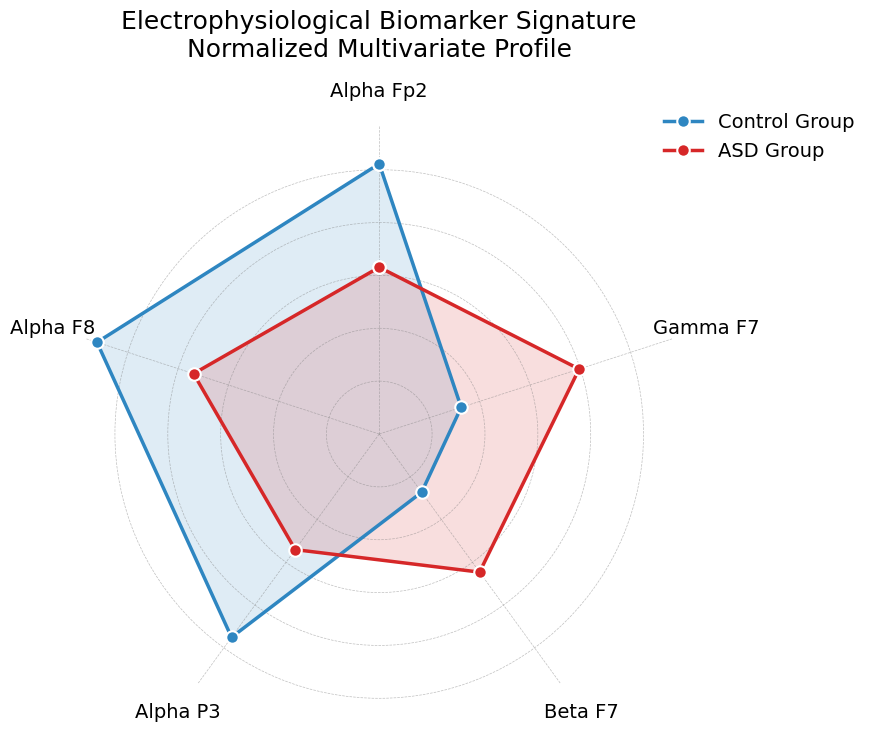

✅ Gráfico de Radar gerado com sucesso, agora com os marcadores (bolinhas) destacados nos vértices!


In [ ]:
# 13. ASSINATURA BIOMARCADORA (RADAR CHART) - COM MARCADORES NOS VÉRTICES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 18,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

# Filtrar a condição de interesse e calcular a média por sujeito
df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# 3. Definição das Features de Ouro e Normalização Crítica
features_ouro = ['AlphaRel_Fp2', 'GammaRel_F7', 'BetaRel_F7', 'AlphaRel_P3', 'AlphaRel_F8']
nomes_limpos = ['Alpha Fp2', 'Gamma F7', 'Beta F7', 'Alpha P3', 'Alpha F8']

# É fundamental normalizar de 0 a 1 para que bandas de baixa magnitude (ex: Gamma) 
# não sumam no gráfico perto de bandas de alta magnitude (ex: Alpha).
scaler = MinMaxScaler()
df_scaled = df_f.copy()
df_scaled[features_ouro] = scaler.fit_transform(df_f[features_ouro])

# 4. Cálculo do "Perfil Médio" (Assinatura) para cada grupo
y = df_scaled['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# Extraindo as médias normalizadas e fechando o polígono do radar (repetindo o primeiro valor no final)
media_tea = df_scaled[y == 1][features_ouro].mean().values.tolist()
media_tea += media_tea[:1] 

media_ctrl = df_scaled[y == 0][features_ouro].mean().values.tolist()
media_ctrl += media_ctrl[:1]

# 5. Configuração da Geometria do Radar (Ângulos)
angulos = np.linspace(0, 2 * np.pi, len(features_ouro), endpoint=False).tolist()
angulos += angulos[:1]

# 6. Plotagem do Gráfico de Radar
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Rotacionar o gráfico para que o primeiro ponto (Alpha Fp2) fique no topo
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Eixos e Rótulos (Nomes das features)
ax.set_xticks(angulos[:-1])
ax.set_xticklabels(nomes_limpos, fontsize=14, fontweight='normal', color='black')
ax.tick_params(pad=15) # Afasta os rótulos do gráfico

# Remover as linhas concêntricas internas (ticks de Y) para um visual mais limpo
ax.set_yticklabels([])
ax.spines['polar'].set_visible(False)
ax.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Plotando o Grupo Controle (Azul)
# Adicionado marker='o', markersize=9 e markeredgecolor='white'
ax.plot(angulos, media_ctrl, color='#2E86C1', linewidth=2.5, linestyle='solid', 
        marker='o', markersize=9, markeredgecolor='white', markeredgewidth=1.5, label='Control Group')
ax.fill(angulos, media_ctrl, color='#2E86C1', alpha=0.15)

# Plotando o Grupo TEA (Vermelho)
# Adicionado marker='o', markersize=9 e markeredgecolor='white'
ax.plot(angulos, media_tea, color='#D62728', linewidth=2.5, linestyle='solid', 
        marker='o', markersize=9, markeredgecolor='white', markeredgewidth=1.5, label='ASD Group')
ax.fill(angulos, media_tea, color='#D62728', alpha=0.15)

# Título e Legenda
plt.title('Electrophysiological Biomarker Signature\nNormalized Multivariate Profile', 
          fontsize=18, y=1.1, fontweight='normal')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.05), fontsize=14, frameon=False)

# 7. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_fig = '../reports/figures/fig_radar_signature.png'
plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico de Radar gerado com sucesso, agora com os marcadores (bolinhas) destacados nos vértices!")

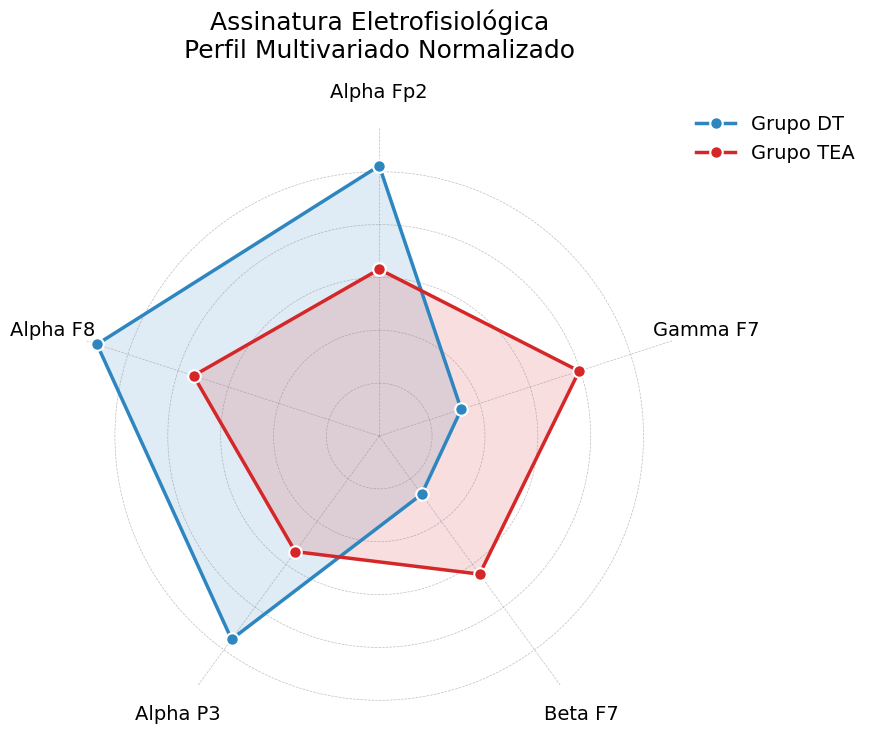

✅ Gráfico de Radar gerado com sucesso, agora com os marcadores (bolinhas) destacados nos vértices!


In [23]:
# 13. ASSINATURA BIOMARCADORA (RADAR CHART) - COM MARCADORES NOS VÉRTICES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import os
import warnings

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 18,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Carregamento e Preparação dos Dados
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

# Filtrar a condição de interesse e calcular a média por sujeito
df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

# 3. Definição das Features de Ouro e Normalização Crítica
features_ouro = ['AlphaRel_Fp2', 'GammaRel_F7', 'BetaRel_F7', 'AlphaRel_P3', 'AlphaRel_F8']
nomes_limpos = ['Alpha Fp2', 'Gamma F7', 'Beta F7', 'Alpha P3', 'Alpha F8']

# É fundamental normalizar de 0 a 1 para que bandas de baixa magnitude (ex: Gamma) 
# não sumam no gráfico perto de bandas de alta magnitude (ex: Alpha).
scaler = MinMaxScaler()
df_scaled = df_f.copy()
df_scaled[features_ouro] = scaler.fit_transform(df_f[features_ouro])

# 4. Cálculo do "Perfil Médio" (Assinatura) para cada grupo
y = df_scaled['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

# Extraindo as médias normalizadas e fechando o polígono do radar (repetindo o primeiro valor no final)
media_tea = df_scaled[y == 1][features_ouro].mean().values.tolist()
media_tea += media_tea[:1] 

media_ctrl = df_scaled[y == 0][features_ouro].mean().values.tolist()
media_ctrl += media_ctrl[:1]

# 5. Configuração da Geometria do Radar (Ângulos)
angulos = np.linspace(0, 2 * np.pi, len(features_ouro), endpoint=False).tolist()
angulos += angulos[:1]

# 6. Plotagem do Gráfico de Radar
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# Rotacionar o gráfico para que o primeiro ponto (Alpha Fp2) fique no topo
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Eixos e Rótulos (Nomes das features)
ax.set_xticks(angulos[:-1])
ax.set_xticklabels(nomes_limpos, fontsize=14, fontweight='normal', color='black')
ax.tick_params(pad=15) # Afasta os rótulos do gráfico

# Remover as linhas concêntricas internas (ticks de Y) para um visual mais limpo
ax.set_yticklabels([])
ax.spines['polar'].set_visible(False)
ax.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Plotando o Grupo Controle (Azul)
# Adicionado marker='o', markersize=9 e markeredgecolor='white'
ax.plot(angulos, media_ctrl, color='#2E86C1', linewidth=2.5, linestyle='solid', 
        marker='o', markersize=9, markeredgecolor='white', markeredgewidth=1.5, label='Grupo DT')
ax.fill(angulos, media_ctrl, color='#2E86C1', alpha=0.15)

# Plotando o Grupo TEA (Vermelho)
# Adicionado marker='o', markersize=9 e markeredgecolor='white'
ax.plot(angulos, media_tea, color='#D62728', linewidth=2.5, linestyle='solid', 
        marker='o', markersize=9, markeredgecolor='white', markeredgewidth=1.5, label='Grupo TEA')
ax.fill(angulos, media_tea, color='#D62728', alpha=0.15)

# Título e Legenda
plt.title('Assinatura Eletrofisiológica\nPerfil Multivariado Normalizado', 
          fontsize=18, y=1.1, fontweight='normal')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.05), fontsize=14, frameon=False)

# 7. Salvamento
os.makedirs('../reports/figures', exist_ok=True)
caminho_fig = '../reports/figures/fig_radar_signature.png'
plt.savefig(caminho_fig, dpi=300, bbox_inches='tight')
plt.show()

print("✅ Gráfico de Radar gerado com sucesso, agora com os marcadores (bolinhas) destacados nos vértices!")

✅ Painel 3x3 de Topomaps gerado e salvo em: ../reports/figures/fig03_comprehensive_topomaps_3x3.png


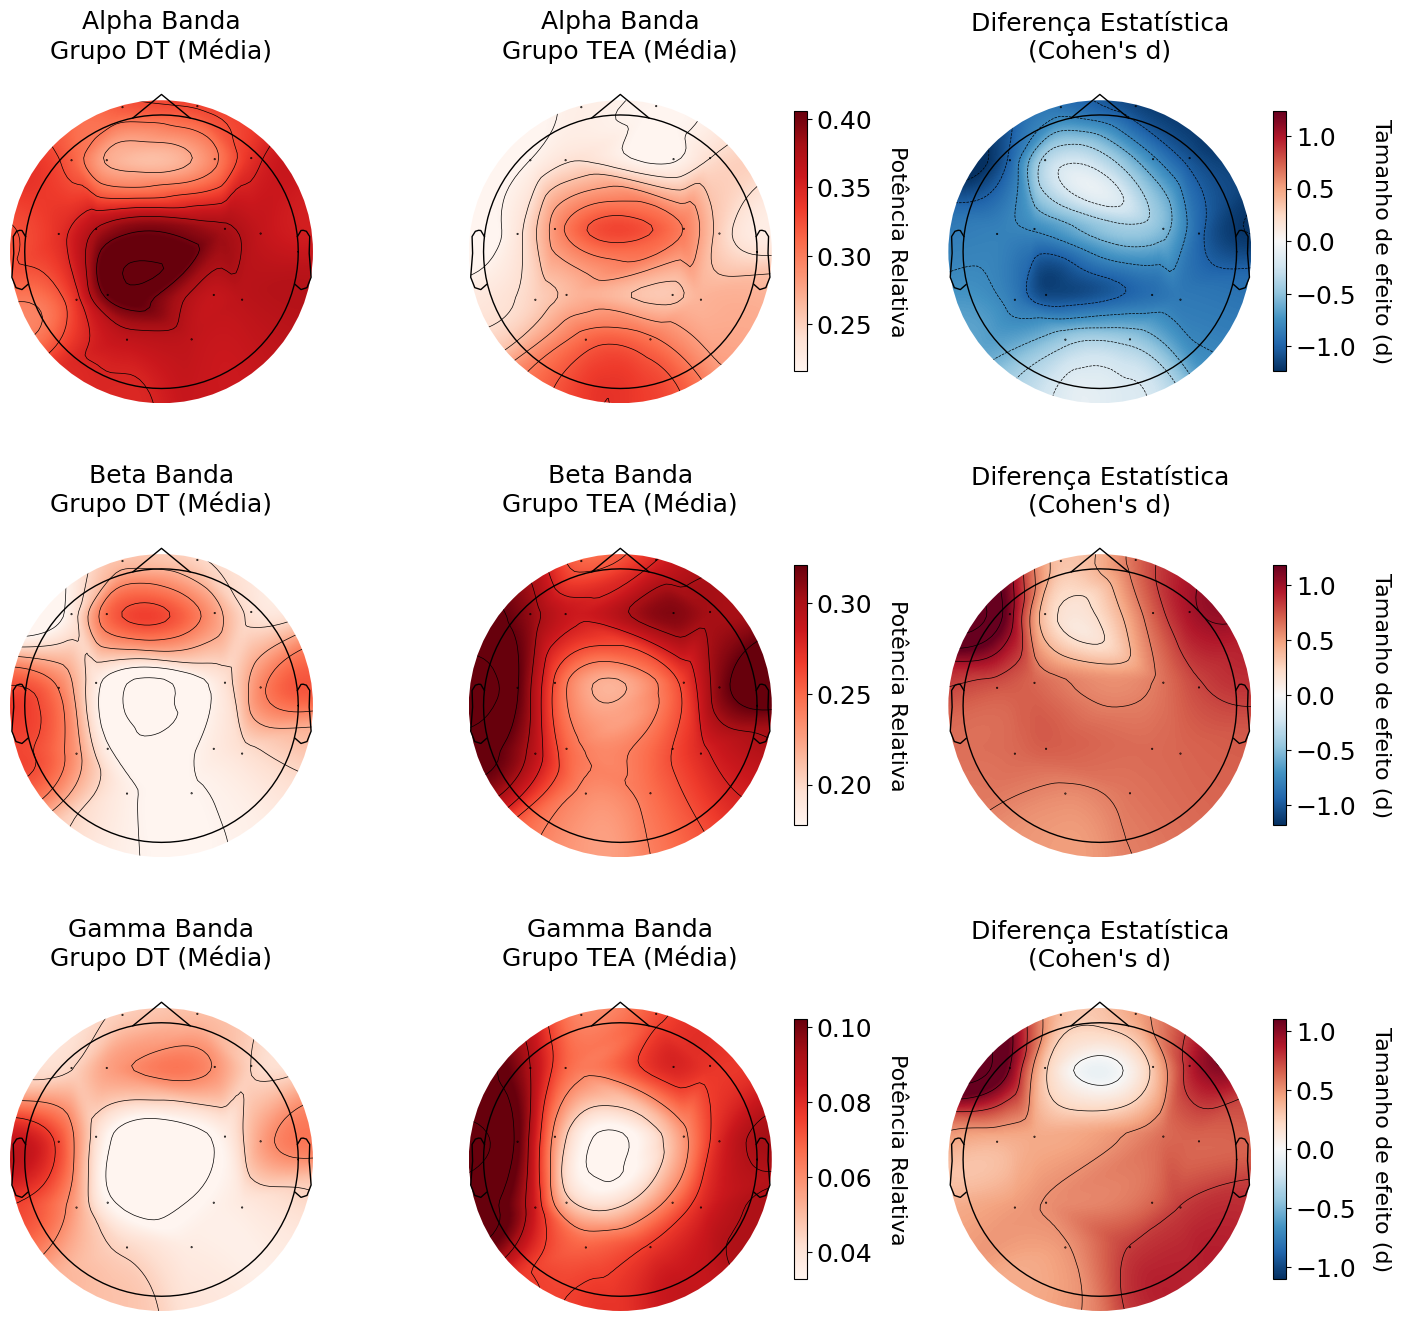

In [2]:
# 08. VISUALIZAÇÃO ALTERNATIVA: COMPREHENSIVE EEG DIFFERENCES (3x3 GRID)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

try:
    import mne
except ImportError:
    print("⚠️ A biblioteca 'mne' não está instalada. Execute '!pip install mne' e rode novamente.")
    mne = None

warnings.filterwarnings("ignore")

# 1. Configurações Visuais
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white'
})

# 2. Função de cálculo do Cohen's d (Segura contra NaNs)
def calcular_cohens_d(grupo1, grupo2):
    g1 = pd.to_numeric(grupo1, errors='coerce').dropna()
    g2 = pd.to_numeric(grupo2, errors='coerce').dropna()
    
    if len(g1) < 2 or len(g2) < 2:
        return 0.0  
        
    n1, n2 = len(g1), len(g2)
    var1, var2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    s_pooled = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    d = (np.mean(g1) - np.mean(g2)) / s_pooled
    return d

# Função para calcular média segura contra NaNs
def calcular_media_segura(grupo):
    g = pd.to_numeric(grupo, errors='coerce').dropna()
    return np.mean(g) if len(g) > 0 else 0.0

# 3. Carregamento e Isolamento (Apenas Face Feliz)
caminho_csv = '../reports/tabela_features_eeg_completa.csv'
df = pd.read_csv(caminho_csv)

df_f = df[df['Condicao'] == 'Face Feliz'].copy()
df_f = df_f.groupby(['ID', 'Grupo']).mean(numeric_only=True).reset_index()

y = df_f['Grupo'].apply(lambda x: 1 if 'TEA' in x else 0).values

df_tea = df_f[y == 1]
df_ctrl = df_f[y == 0]

# 4. Configuração das Bandas
bandas = ['Alpha', 'Beta', 'Gamma']
canais = [col.split('_')[1] for col in df_f.columns if col.startswith('AlphaRel_')]

if mne is not None:
    # Estrutura MNE Padrão 10-20
    info = mne.create_info(ch_names=canais, sfreq=1000, ch_types='eeg')
    montage = mne.channels.make_standard_montage('standard_1020')
    info.set_montage(montage)

    # 5. Preparação da Grade de Plotagem (3 linhas x 3 colunas)
    fig, axes = plt.subplots(3, 3, figsize=(18, 16))
    
    for i, banda in enumerate(bandas):
        medias_ctrl = []
        medias_tea = []
        d_vals = []
        
        # Extração dos dados por canal para a banda atual
        for canal in canais:
            feature_name = f'{banda}Rel_{canal}'
            
            m_ctrl = calcular_media_segura(df_ctrl[feature_name])
            m_tea = calcular_media_segura(df_tea[feature_name])
            d = calcular_cohens_d(df_tea[feature_name], df_ctrl[feature_name])
            
            medias_ctrl.append(m_ctrl)
            medias_tea.append(m_tea)
            d_vals.append(d)
            
        medias_ctrl = np.array(medias_ctrl)
        medias_tea = np.array(medias_tea)
        d_vals = np.array(d_vals)
        
        # Escala compartilhada de Potência Relativa (mínimo e máximo entre ambos os grupos)
        vmin_pwr = min(np.min(medias_ctrl), np.min(medias_tea))
        vmax_pwr = max(np.max(medias_ctrl), np.max(medias_tea))
        
        # Escala simétrica para o Cohen's d divergente
        vmax_d = np.max(np.abs(d_vals)) * 1.1
        vmin_d = -vmax_d if vmax_d > 0 else -1.0
        vmax_d = vmax_d if vmax_d > 0 else 1.0

        # --- COLUNA 1: Grupo Controle (Média) ---
        im_ctrl, _ = mne.viz.plot_topomap(medias_ctrl, info, axes=axes[i, 0], show=False, 
                                          cmap='Reds', vlim=(vmin_pwr, vmax_pwr),
                                          extrapolate='head', contours=6)
        axes[i, 0].set_title(f'{banda} Banda\nGrupo DT (Média)', pad=15)

        # --- COLUNA 2: Grupo TEA (Média) ---
        im_tea, _ = mne.viz.plot_topomap(medias_tea, info, axes=axes[i, 1], show=False, 
                                         cmap='Reds', vlim=(vmin_pwr, vmax_pwr),
                                         extrapolate='head', contours=6)
        axes[i, 1].set_title(f'{banda} Banda\nGrupo TEA (Média)', pad=15)
        
        # Barra de Cores para a Potência Relativa (Ao lado da Coluna 2)
        cbar1 = fig.colorbar(im_tea, ax=axes[i, 1], shrink=0.8, pad=0.05)
        cbar1.set_label('Potência Relativa', rotation=270, labelpad=25)

        # --- COLUNA 3: Diferença Estatística (Cohen's d) ---
        im_d, _ = mne.viz.plot_topomap(d_vals, info, axes=axes[i, 2], show=False, 
                                       cmap='RdBu_r', vlim=(vmin_d, vmax_d),
                                       extrapolate='head', contours=6)
        axes[i, 2].set_title(f'Diferença Estatística\n(Cohen\'s d)', pad=15)
        
        # Barra de Cores para o Cohen's d (Ao lado da Coluna 3)
        cbar2 = fig.colorbar(im_d, ax=axes[i, 2], shrink=0.8, pad=0.05)
        cbar2.set_label('Tamanho de efeito (d)', rotation=270, labelpad=25)

    # Ajustes finais de espaçamento da grade
    plt.subplots_adjust(hspace=0.4, wspace=0.1)

    # 6. Salvamento
    os.makedirs('../reports/figures', exist_ok=True)
    caminho_imagem = '../reports/figures/fig03_comprehensive_topomaps_3x3.png'
    plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
    print(f"✅ Painel 3x3 de Topomaps gerado e salvo em: {caminho_imagem}")
    plt.show()